# Trading research: recent data only

This rebuild uses **192 observations from September 24–October 31, 2026**. The three June observations are excluded.
The original source files and previous full-history notebook are preserved.

**Approved so far:** (1) date/row/gap audit; (2) BTC/score charts and relationships with subsequent 1, 4, 12 and 24-hour returns.
Also approved: separate P-score-only, news-score-only and technical-score-only views, each with its own price context, correlation table and forward-return scatter plots.

**Also approved:** recent-only threshold and holding-period comparisons for the original 70/30 P-score, with no leverage.

**Also approved:** the same recent-only threshold/holding-period comparison using the news score alone.

**Also approved:** the same recent-only threshold/holding-period comparison using the technical score alone.

**Also approved:** 21 recent-only news/TA weight combinations, with a fixed 24-hour hold and thresholds selected on earlier observations.

Additional chronology checks, cost/delay stress, new filters, leverage models and other studies have **not** been rerun.
They will be added only after separate approval.

The exported HOLD labels are placeholders. This stage studies continuous P-scores, news scores and technical scores.
The price input is an independent frozen Binance hourly dataset. No API calls, credentials, bot imports or application changes are required.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display

candidates=[Path.cwd(),Path.cwd()/"notebooks"]
RESEARCH_DIR=next((p for p in candidates if (p/"recent_data"/"signals_recent.csv").exists()),None)
if RESEARCH_DIR is None:
    raise FileNotFoundError("Run from the project root or notebooks folder, with recent_data beside this notebook.")
DATA_DIR=RESEARCH_DIR/"recent_data"
RESULTS_DIR=RESEARCH_DIR/"results_recent"
RESULTS_DIR.mkdir(exist_ok=True)
manifest=json.loads((DATA_DIR/"manifest.json").read_text(encoding="utf-8"))
for name,expected in manifest["files"].items():
    assert hashlib.sha256((DATA_DIR/name).read_bytes()).hexdigest()==expected
signals=pd.read_csv(DATA_DIR/"signals_recent.csv")
signals["timestamp"]=pd.to_datetime(signals.timestamp,utc=True)
signals=signals.sort_values("timestamp").reset_index(drop=True)
market=pd.read_csv(DATA_DIR/"btc_hourly_recent.csv")
for col in ["open_time","close_time"]:
    market[col]=pd.to_datetime(market[col],utc=True)
P=market.set_index("open_time").open
signals["previous_timestamp"]=signals.timestamp.shift(1)
signals["gap_hours"]=signals.timestamp.diff().dt.total_seconds()/3600
assert len(signals)==192
assert signals.timestamp.ge(pd.Timestamp("2026-09-01",tz="UTC")).all()
assert not signals.duplicated(["timestamp","symbol"]).any()
assert signals[["p_score","news_score","ta_score","current_price"]].notna().all().all()
assert market.open_time.diff().dropna().eq(pd.Timedelta(hours=1)).all()
plt.rcParams.update({"font.size":10,"axes.spines.top":False,"axes.spines.right":False})

def show_chart(fig,name):
    fig.savefig(RESULTS_DIR/f"{name}.png",dpi=150,bbox_inches="tight",facecolor="white")
    display(fig)
    plt.close(fig)

## 1. Approved data audit

There are no May records in the original export. Three records from June 5 are excluded.
The recent data still contains interruptions; these remain visible rather than being filled with invented observations.
All times are UTC. The typical collection interval is approximately four hours.

In [2]:
audit=pd.DataFrame([
    ("Original observations",manifest["original_rows"]),
    ("Older observations excluded",manifest["excluded_older_rows"]),
    ("Recent observations",len(signals)),
    ("First recent timestamp (UTC)",str(signals.timestamp.min())),
    ("Last recent timestamp (UTC)",str(signals.timestamp.max())),
    ("Median collection interval (hours)",signals.gap_hours.median()),
    ("Largest recent gap (hours)",signals.gap_hours.max()),
    ("Intervals longer than 12 hours",int(signals.gap_hours.gt(12).sum()))
],columns=["Check","Result"])
gaps=signals.loc[signals.gap_hours.gt(12),["previous_timestamp","timestamp","gap_hours"]]
display(audit)
display(gaps)
audit.to_csv(RESULTS_DIR/"recent_data_audit.csv",index=False)
gaps.to_csv(RESULTS_DIR/"recent_signal_gaps.csv",index=False)

,Check,Result
0,Original observations,195
1,Older observations excluded,3
2,Recent observations,192
3,First recent timestamp (UTC),2026-09-24 20:51:46.882000+00:00
4,Last recent timestamp (UTC),2026-10-31 14:49:26.863000+00:00
5,Median collection interval (hours),4.002057
6,Largest recent gap (hours),51.916129
7,Intervals longer than 12 hours,5


,previous_timestamp,timestamp,gap_hours
2,2026-09-24 21:42:32.374000+00:00,2026-09-26 12:03:47.201000+00:00,38.354119
60,2026-10-06 02:51:20.611000+00:00,2026-10-06 18:49:08.216000+00:00,15.963224
64,2026-10-07 06:48:22.703000+00:00,2026-10-07 22:48:33.474000+00:00,16.002992
70,2026-10-08 18:48:47.848000+00:00,2026-10-09 06:50:20.897000+00:00,12.025847
111,2026-10-16 02:53:40.854000+00:00,2026-10-18 06:48:38.919000+00:00,51.916129


## 2. Approved price and score chart

Circles mark collected observations, not simulated trades. Shading marks intervals exceeding 12 hours between saved scores.
The BTC market-price series remains continuous because market candles exist during those periods. Score lines break across
the gaps. No missing scores are interpolated or forward-filled.

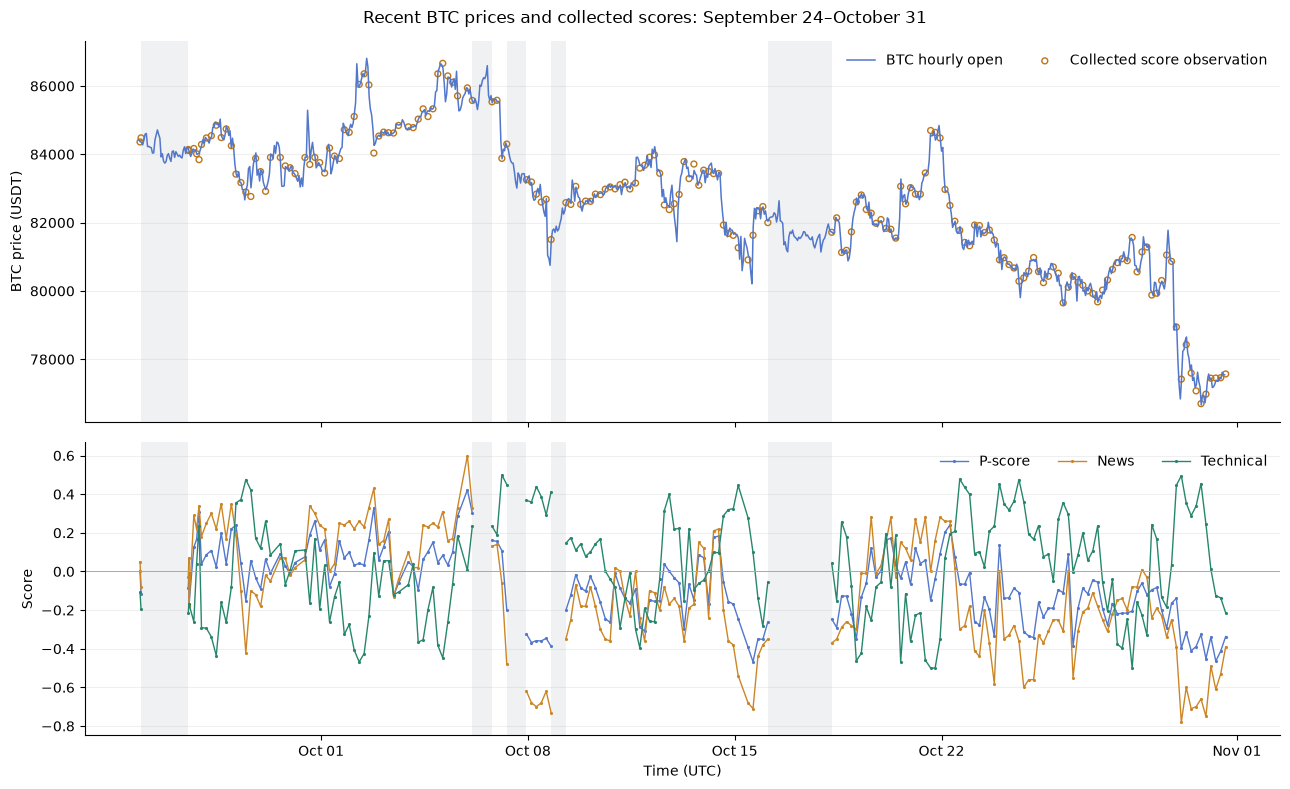

In [3]:
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True,gridspec_kw={"height_ratios":[1.3,1]})
axes[0].plot(market.open_time,market.open,lw=1.1,color="#5277cb",label="BTC hourly open")
axes[0].scatter(signals.timestamp,signals.current_price,s=18,facecolors="none",edgecolors="#bd7617",label="Collected score observation")
axes[0].set_ylabel("BTC price (USDT)")
axes[0].legend(frameon=False,ncol=2)
for col,label,color in [("p_score","P-score","#5277cb"),("news_score","News","#cc8626"),("ta_score","Technical","#27876c")]:
    first=True
    for _,group in signals.groupby(signals.gap_hours.gt(12).cumsum()):
        axes[1].plot(group.timestamp,group[col],".-",lw=1,ms=2.5,color=color,label=label if first else None)
        first=False
for row in gaps.itertuples():
    for ax in axes:
        ax.axvspan(row.previous_timestamp,row.timestamp,color="#8791a1",alpha=.12,lw=0)
axes[1].axhline(0,color="#aaaaaa",lw=.7)
axes[1].set_ylabel("Score")
axes[1].set_xlabel("Time (UTC)")
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5,maxticks=8))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[1].legend(frameon=False,ncol=3)
for ax in axes:ax.grid(axis="y",alpha=.2)
fig.suptitle("Recent BTC prices and collected scores: September 24–October 31")
fig.tight_layout()
show_chart(fig,"recent_btc_and_scores")

## 3. Approved forward-return correlation study

For each score timestamp, use the next hourly open strictly after the timestamp as a prospective entry reference.
Then measure the BTC price change from that open to the open 1, 4, 12 or 24 hours later. This avoids treating the already-known
price at signal capture as a future execution price. This is a price-association study, **not a trading simulation**.

Incomplete final horizons remain missing. Market candles allow forward returns to be measured even when another score
was not collected during the outcome window; no scores are invented. Pearson measures linear association and Spearman
measures rank association. Overlapping horizons, autocorrelation and repeated news events mean rows are not independent.
No significance tests, threshold fitting or strategy selection are performed in this approved stage.

,horizon_hours,score,observations,pearson,spearman
0,1,P-score,191,-0.0567,-0.0543
1,1,News,191,-0.0355,-0.0594
2,1,Technical,191,-0.0380,0.0048
3,4,P-score,190,-0.0074,0.0132
4,4,News,190,-0.0155,0.0052
5,4,Technical,190,0.0237,-0.0200
6,12,P-score,188,0.1039,0.1323
7,12,News,188,0.0453,0.0747
8,12,Technical,188,0.1173,0.0848
9,24,P-score,185,0.0854,0.0983


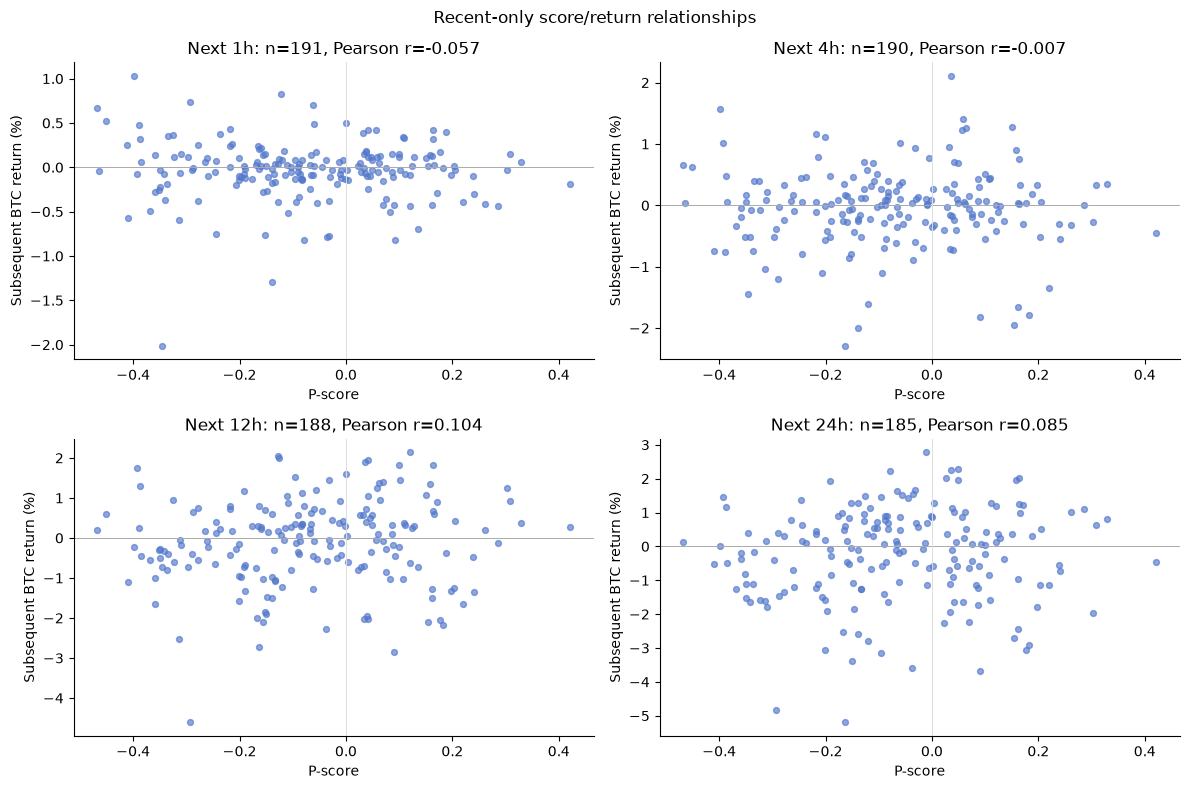

2493

In [4]:
HORIZONS=[1,4,12,24]
signals["entry_time"]=signals.timestamp.dt.floor("h")+pd.Timedelta(hours=1)
signals["entry_open"]=signals.entry_time.map(P)
assert signals.entry_time.gt(signals.timestamp).all()
rows=[]
for h in HORIZONS:
    signals[f"exit_time_{h}h"]=signals.entry_time+pd.Timedelta(hours=h)
    signals[f"exit_open_{h}h"]=signals[f"exit_time_{h}h"].map(P)
    signals[f"forward_return_{h}h"]=signals[f"exit_open_{h}h"]/signals.entry_open-1
    target=f"forward_return_{h}h"
    for column,label in [("p_score","P-score"),("news_score","News"),("ta_score","Technical")]:
        z=signals[[column,target]].dropna()
        rows.append(dict(horizon_hours=h,score=label,observations=len(z),
                         pearson=z[column].corr(z[target]),spearman=z[column].rank().corr(z[target].rank())))
correlations=pd.DataFrame(rows)
display(correlations.round(4))
correlations.to_csv(RESULTS_DIR/"recent_score_correlations.csv",index=False)
signals.to_csv(RESULTS_DIR/"recent_scores_with_forward_returns.csv",index=False)

fig,axes=plt.subplots(2,2,figsize=(12,8))
for ax,h in zip(axes.flat,HORIZONS):
    z=signals.dropna(subset=[f"forward_return_{h}h"])
    r=z.p_score.corr(z[f"forward_return_{h}h"])
    ax.scatter(z.p_score,z[f"forward_return_{h}h"]*100,s=18,alpha=.65,color="#5277cb")
    ax.axhline(0,color="#aaaaaa",lw=.7)
    ax.axvline(0,color="#dddddd",lw=.7)
    ax.set(title=f"Next {h}h: n={len(z)}, Pearson r={r:.3f}",xlabel="P-score",ylabel="Subsequent BTC return (%)")
fig.suptitle("Recent-only score/return relationships")
fig.tight_layout()
show_chart(fig,"recent_forward_return_scatter")

summary=dict(approved_stage=2,retained_observations=len(signals),excluded_older_observations=manifest["excluded_older_rows"],
    first_signal_utc=str(signals.timestamp.min()),last_signal_utc=str(signals.timestamp.max()),
    score_gaps_over_12h=len(gaps),last_available_hourly_open_utc=str(P.index.max()),
    correlations=correlations.to_dict("records"),
    limitation="Descriptive association only; overlapping returns and dependent observations; no threshold fitting or backtest.")
(RESULTS_DIR/"recent_stage_02_results.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")

## 4. P-score only

This view isolates **p-score** while keeping the same recent observations, market prices, execution reference and return horizons.
The first chart shows BTC above this score alone. Shaded intervals mark collection gaps longer than 12 hours; the score line breaks there.
The table and four scatter plots measure this score against **subsequent BTC returns**, starting at the next hourly open.
These are descriptive associations, not simulated trading outcomes or a threshold search.


,horizon_hours,observations,pearson,spearman
0,1,191,-0.0567,-0.0543
3,4,190,-0.0074,0.0132
6,12,188,0.1039,0.1323
9,24,185,0.0854,0.0983


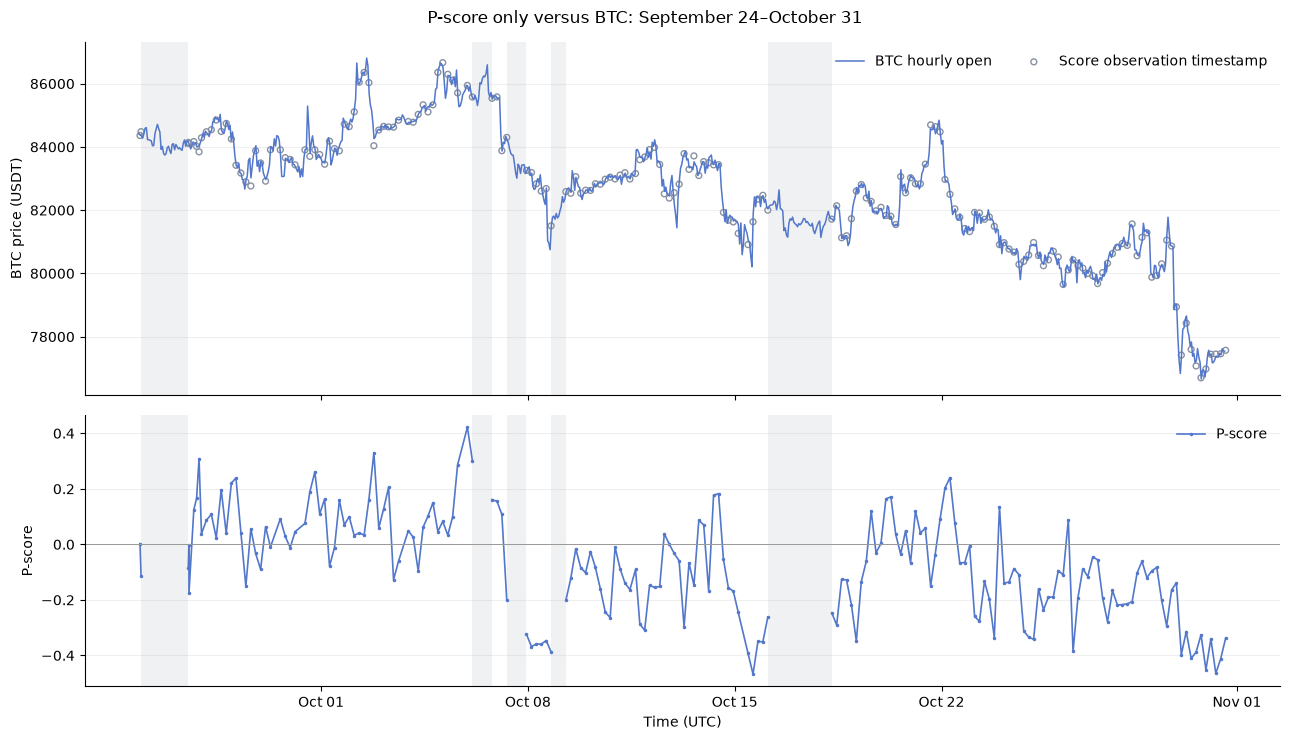

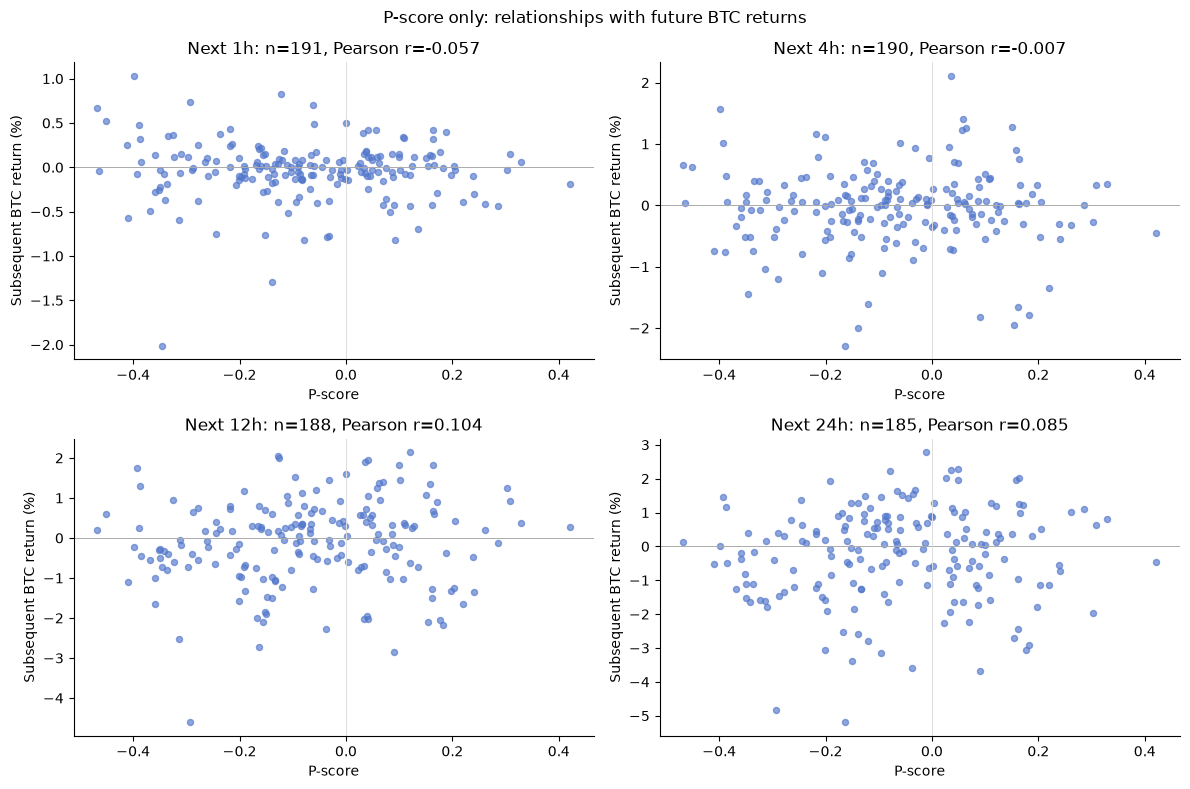

In [5]:
# Isolated score view. No threshold fitting or trading simulation.
score_column = 'p_score'
score_title = 'P-score'
score_slug = 'p_score'
score_table_label = 'P-score'
score_color = '#5277cb'
score_table = correlations.loc[correlations.score.eq(score_table_label),
    ["horizon_hours", "observations", "pearson", "spearman"]].copy()
display(score_table.round(4))
score_table.to_csv(RESULTS_DIR / f"{score_slug}_only_correlations.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].plot(market.open_time, market.open, color="#5277cb", lw=1.1, label="BTC hourly open")
axes[0].scatter(signals.timestamp, signals.current_price, s=18, facecolors="none",
                edgecolors="#8791a1", label="Score observation timestamp")
axes[0].set_ylabel("BTC price (USDT)")
axes[0].legend(frameon=False, ncol=2)
first = True
for _, group in signals.groupby(signals.gap_hours.gt(12).cumsum()):
    axes[1].plot(group.timestamp, group[score_column], ".-", lw=1.2, ms=3,
                 color=score_color, label=score_title if first else None)
    first = False
for gap in gaps.itertuples():
    for ax in axes:
        ax.axvspan(gap.previous_timestamp, gap.timestamp, color="#8791a1", alpha=.12, lw=0)
axes[1].axhline(0, color="#999999", lw=.7)
axes[1].set_ylabel(score_title)
axes[1].set_xlabel("Time (UTC)")
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=8))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.suptitle(f"{score_title} only versus BTC: September 24–October 31")
fig.tight_layout()
show_chart(fig, f"{score_slug}_only_price_context")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, h in zip(axes.flat, HORIZONS):
    z = signals.dropna(subset=[score_column, f"forward_return_{h}h"])
    pearson = z[score_column].corr(z[f"forward_return_{h}h"])
    ax.scatter(z[score_column], z[f"forward_return_{h}h"] * 100,
               s=19, alpha=.65, color=score_color)
    ax.axhline(0, color="#aaaaaa", lw=.7)
    ax.axvline(0, color="#dddddd", lw=.7)
    ax.set(title=f"Next {h}h: n={len(z)}, Pearson r={pearson:.3f}",
           xlabel=score_title, ylabel="Subsequent BTC return (%)")
fig.suptitle(f"{score_title} only: relationships with future BTC returns")
fig.tight_layout()
show_chart(fig, f"{score_slug}_only_forward_scatter")

## 5. News score only

This view isolates **news score** while keeping the same recent observations, market prices, execution reference and return horizons.
The first chart shows BTC above this score alone. Shaded intervals mark collection gaps longer than 12 hours; the score line breaks there.
The table and four scatter plots measure this score against **subsequent BTC returns**, starting at the next hourly open.
These are descriptive associations, not simulated trading outcomes or a threshold search.


,horizon_hours,observations,pearson,spearman
1,1,191,-0.0355,-0.0594
4,4,190,-0.0155,0.0052
7,12,188,0.0453,0.0747
10,24,185,0.0093,0.0259


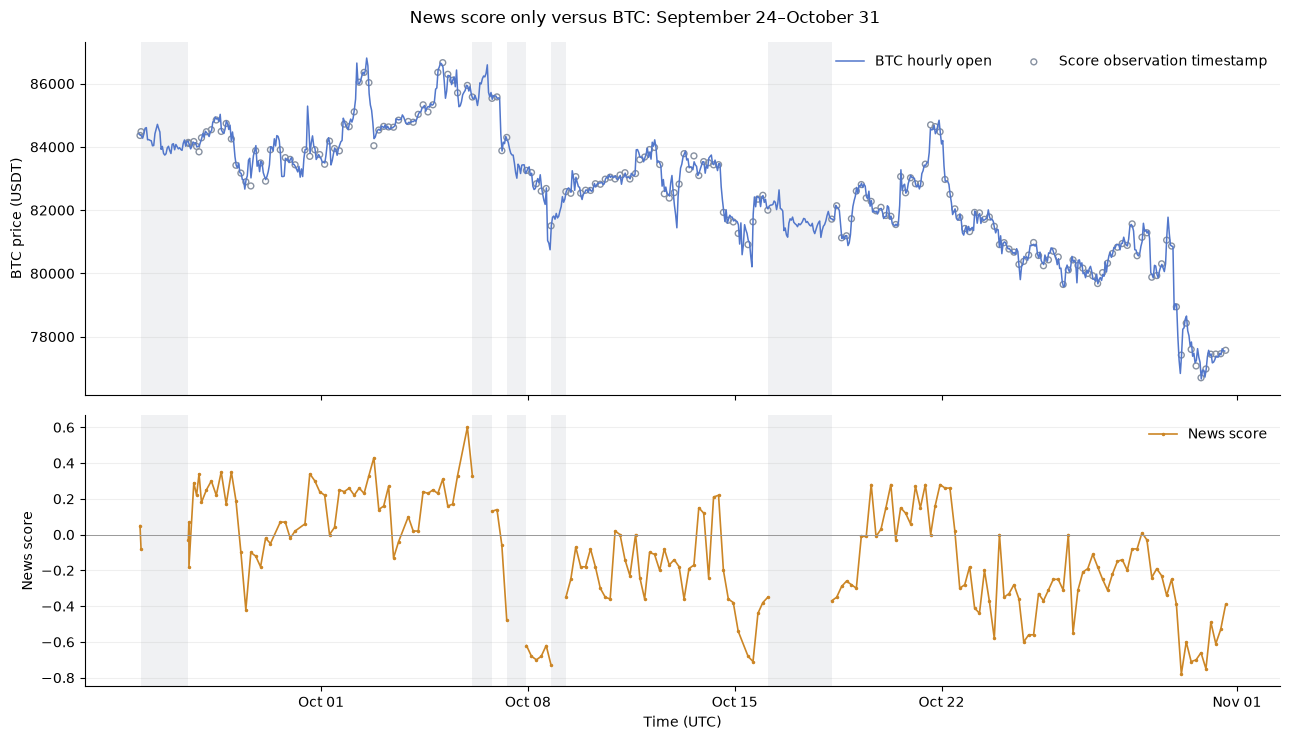

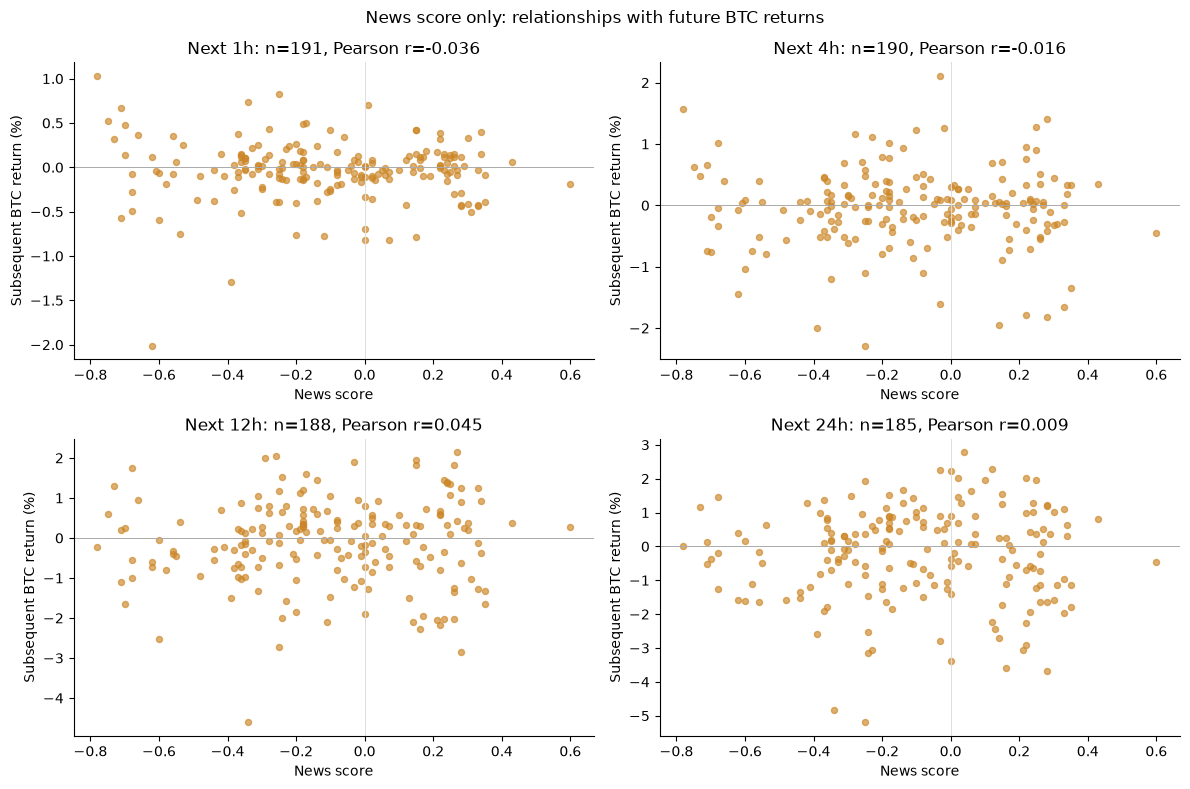

In [6]:
# Isolated score view. No threshold fitting or trading simulation.
score_column = 'news_score'
score_title = 'News score'
score_slug = 'news_score'
score_table_label = 'News'
score_color = '#cc8626'
score_table = correlations.loc[correlations.score.eq(score_table_label),
    ["horizon_hours", "observations", "pearson", "spearman"]].copy()
display(score_table.round(4))
score_table.to_csv(RESULTS_DIR / f"{score_slug}_only_correlations.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].plot(market.open_time, market.open, color="#5277cb", lw=1.1, label="BTC hourly open")
axes[0].scatter(signals.timestamp, signals.current_price, s=18, facecolors="none",
                edgecolors="#8791a1", label="Score observation timestamp")
axes[0].set_ylabel("BTC price (USDT)")
axes[0].legend(frameon=False, ncol=2)
first = True
for _, group in signals.groupby(signals.gap_hours.gt(12).cumsum()):
    axes[1].plot(group.timestamp, group[score_column], ".-", lw=1.2, ms=3,
                 color=score_color, label=score_title if first else None)
    first = False
for gap in gaps.itertuples():
    for ax in axes:
        ax.axvspan(gap.previous_timestamp, gap.timestamp, color="#8791a1", alpha=.12, lw=0)
axes[1].axhline(0, color="#999999", lw=.7)
axes[1].set_ylabel(score_title)
axes[1].set_xlabel("Time (UTC)")
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=8))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.suptitle(f"{score_title} only versus BTC: September 24–October 31")
fig.tight_layout()
show_chart(fig, f"{score_slug}_only_price_context")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, h in zip(axes.flat, HORIZONS):
    z = signals.dropna(subset=[score_column, f"forward_return_{h}h"])
    pearson = z[score_column].corr(z[f"forward_return_{h}h"])
    ax.scatter(z[score_column], z[f"forward_return_{h}h"] * 100,
               s=19, alpha=.65, color=score_color)
    ax.axhline(0, color="#aaaaaa", lw=.7)
    ax.axvline(0, color="#dddddd", lw=.7)
    ax.set(title=f"Next {h}h: n={len(z)}, Pearson r={pearson:.3f}",
           xlabel=score_title, ylabel="Subsequent BTC return (%)")
fig.suptitle(f"{score_title} only: relationships with future BTC returns")
fig.tight_layout()
show_chart(fig, f"{score_slug}_only_forward_scatter")

## 6. Technical score only

This view isolates **technical score** while keeping the same recent observations, market prices, execution reference and return horizons.
The first chart shows BTC above this score alone. Shaded intervals mark collection gaps longer than 12 hours; the score line breaks there.
The table and four scatter plots measure this score against **subsequent BTC returns**, starting at the next hourly open.
These are descriptive associations, not simulated trading outcomes or a threshold search.


,horizon_hours,observations,pearson,spearman
2,1,191,-0.0380,0.0048
5,4,190,0.0237,-0.0200
8,12,188,0.1173,0.0848
11,24,185,0.1668,0.1504


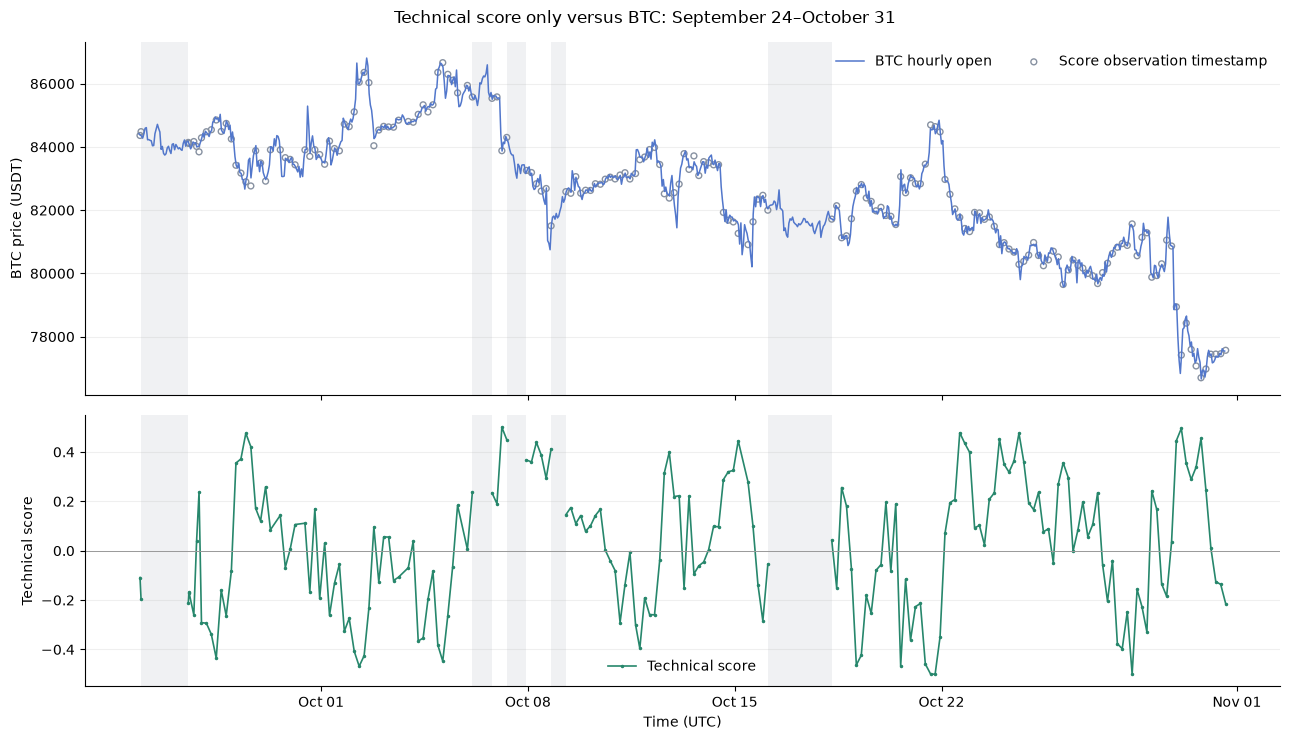

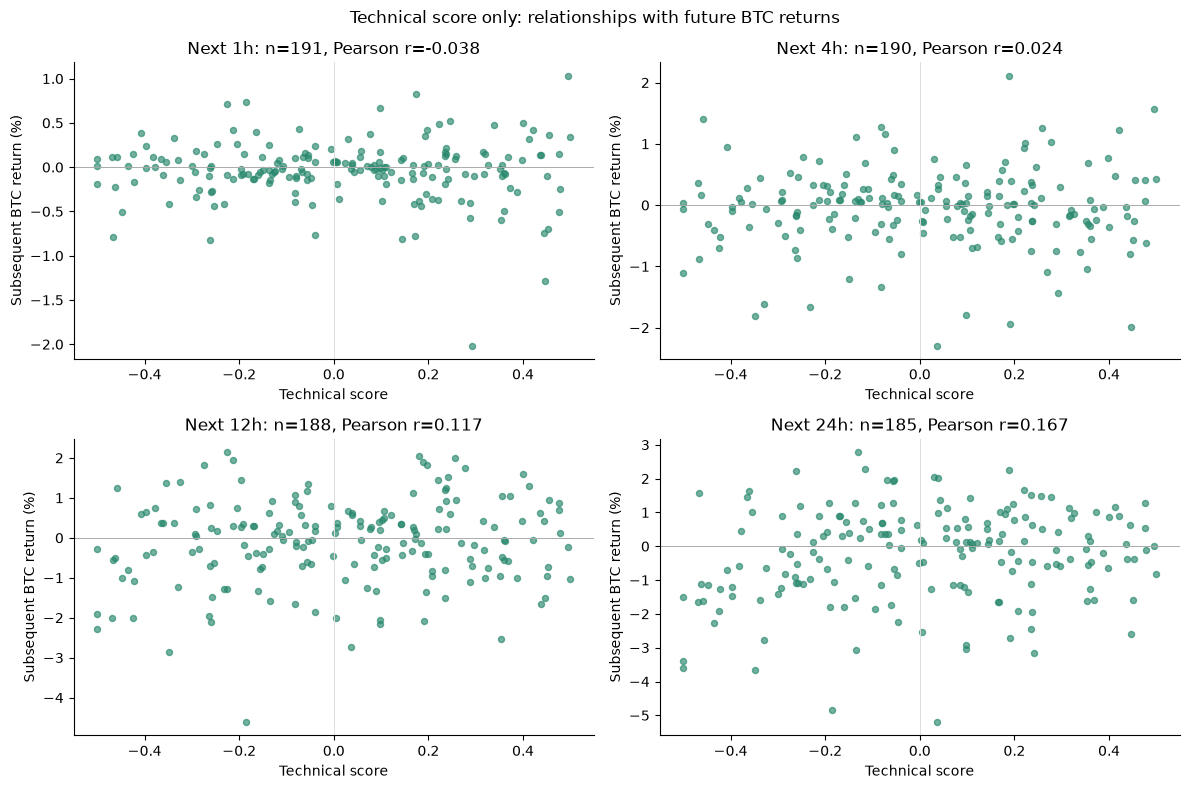

In [7]:
# Isolated score view. No threshold fitting or trading simulation.
score_column = 'ta_score'
score_title = 'Technical score'
score_slug = 'ta_score'
score_table_label = 'Technical'
score_color = '#27876c'
score_table = correlations.loc[correlations.score.eq(score_table_label),
    ["horizon_hours", "observations", "pearson", "spearman"]].copy()
display(score_table.round(4))
score_table.to_csv(RESULTS_DIR / f"{score_slug}_only_correlations.csv", index=False)

fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True,
                         gridspec_kw={"height_ratios": [1.3, 1]})
axes[0].plot(market.open_time, market.open, color="#5277cb", lw=1.1, label="BTC hourly open")
axes[0].scatter(signals.timestamp, signals.current_price, s=18, facecolors="none",
                edgecolors="#8791a1", label="Score observation timestamp")
axes[0].set_ylabel("BTC price (USDT)")
axes[0].legend(frameon=False, ncol=2)
first = True
for _, group in signals.groupby(signals.gap_hours.gt(12).cumsum()):
    axes[1].plot(group.timestamp, group[score_column], ".-", lw=1.2, ms=3,
                 color=score_color, label=score_title if first else None)
    first = False
for gap in gaps.itertuples():
    for ax in axes:
        ax.axvspan(gap.previous_timestamp, gap.timestamp, color="#8791a1", alpha=.12, lw=0)
axes[1].axhline(0, color="#999999", lw=.7)
axes[1].set_ylabel(score_title)
axes[1].set_xlabel("Time (UTC)")
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5, maxticks=8))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
for ax in axes:
    ax.grid(axis="y", alpha=.2)
fig.suptitle(f"{score_title} only versus BTC: September 24–October 31")
fig.tight_layout()
show_chart(fig, f"{score_slug}_only_price_context")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, h in zip(axes.flat, HORIZONS):
    z = signals.dropna(subset=[score_column, f"forward_return_{h}h"])
    pearson = z[score_column].corr(z[f"forward_return_{h}h"])
    ax.scatter(z[score_column], z[f"forward_return_{h}h"] * 100,
               s=19, alpha=.65, color=score_color)
    ax.axhline(0, color="#aaaaaa", lw=.7)
    ax.axvline(0, color="#dddddd", lw=.7)
    ax.set(title=f"Next {h}h: n={len(z)}, Pearson r={pearson:.3f}",
           xlabel=score_title, ylabel="Subsequent BTC return (%)")
fig.suptitle(f"{score_title} only: relationships with future BTC returns")
fig.tight_layout()
show_chart(fig, f"{score_slug}_only_forward_scatter")

## 7. Approved recent-only threshold and holding-period comparison: P-score

This stage generates hypothetical trades from the original 70/30 **P-score**, ignoring the placeholder HOLD labels.
It tests thresholds **0.05–0.55 in 0.05 steps** and holding periods **1, 4, 8, 12, 24 and 48 hours**, separately for:

- **Buying only:** enter long when P-score reaches the positive threshold; otherwise stay in cash.
- **Long and short:** also enter short when P-score reaches the negative threshold of the same magnitude.

Execution assumptions are fixed before comparing results:

- 1,000 USDT starting capital; one position at a time; **no leverage**. Gross entry notional plus entry fees stays within equity.
- Entry is the next hourly open strictly after the score timestamp. Exit is the hourly open after the specified duration.
- Signals whose scheduled entries overlap an open position are skipped. An entry scheduled at an existing exit time may execute.
- Fees are **0.10% per side**, and adverse slippage is **0.05% per side**. These are assumed costs, not verified account rates.
- No stop-loss or take-profit rules are inferred from missing historical levels. Hypothetical shorts exclude funding, borrow costs,
  margin requirements and liquidation mechanics. This is not a complete futures backtest.
- Incomplete final holding windows are skipped. Collection gaps stay visible; price data is available across those gaps.

Use the first 70% of the **192 recent observations** for selection and the remaining 30% for a chronological later-period check.
Choose each mode's threshold/hold pair by earlier net return, requiring at least **10 earlier completed trades**. Ties favor more trades.
Each segment starts with fresh cash; no trade crosses the segment boundary. These data were already inspected, so the later
check is **not a pristine untouched holdout**. Negative training winners are shown honestly and do not imply a recommendation to trade.

In [8]:
THRESHOLD_GRID=[round(x,2) for x in np.arange(.05,.551,.05)]
HOLD_GRID=[1,4,8,12,24,48]
MODES=["Buying only","Long and short"]
STARTING_EQUITY=1000.
FEE_RATE=.001
SLIPPAGE_RATE=.0005
MIN_TRAINING_TRADES=10
RECENT_N=len(signals)
RECENT_CUT=int(RECENT_N*.7)
RECENT_SPLIT=signals.timestamp.iloc[RECENT_CUT]
RECENT_END=P.index.max()
SEGMENTS=[("Earlier",0,RECENT_CUT),("Later",RECENT_CUT,RECENT_N),("Full recent sample",0,RECENT_N)]
PRICE_LOOKUP=P.to_dict()
SIMULATIONS={}
TRADE_COLS=["source_row","signal_time","entry_time","exit_time","side","p_score","entry_open","exit_open",
            "entry_fill","exit_fill","quantity","initial_equity","ending_equity","net_pnl","net_return","fees","signal_score","score_column"]

def simulate_recent_score(score_column,threshold,holding_hours,mode,begin,end):
    key=(score_column,threshold,holding_hours,mode,begin,end)
    if key in SIMULATIONS:
        return SIMULATIONS[key]
    start=signals.entry_time.iloc[begin]
    finish=RECENT_END if end==RECENT_N else signals.timestamp.iloc[end].floor("h")
    capital=STARTING_EQUITY
    next_free=start
    trades=[]
    curve=pd.Series(np.nan,index=P.loc[start:finish].index,dtype=float)
    curve.iloc[0]=capital
    for i in range(begin,end):
        row=signals.iloc[i]
        signal_score=float(row[score_column])
        side=1 if signal_score>=threshold else (-1 if mode=="Long and short" and signal_score<=-threshold else 0)
        if not side:
            continue
        entry=row.entry_time
        exit_time=entry+pd.Timedelta(hours=holding_hours)
        if entry<start or entry<next_free or exit_time>finish or entry not in PRICE_LOOKUP or exit_time not in PRICE_LOOKUP:
            continue
        entry_mid=float(PRICE_LOOKUP[entry]);exit_mid=float(PRICE_LOOKUP[exit_time])
        entry_fill=entry_mid*(1+side*SLIPPAGE_RATE)
        exit_fill=exit_mid*(1-side*SLIPPAGE_RATE)
        quantity=capital/(entry_fill*(1+FEE_RATE))
        fee_in=quantity*entry_fill*FEE_RATE
        fee_out=quantity*exit_fill*FEE_RATE
        final=capital-fee_in+side*quantity*(exit_fill-entry_fill)-fee_out
        assert final>0,"Equity exhausted; liquidation is not implemented in this model."
        marks=P.loc[entry:exit_time].iloc[:-1]
        curve.loc[marks.index]=capital-fee_in+side*quantity*(marks-entry_fill)
        curve.loc[exit_time]=final
        trades.append(dict(source_row=i,signal_time=row.timestamp,entry_time=entry,exit_time=exit_time,
            side=side,p_score=row.p_score,signal_score=signal_score,score_column=score_column,entry_open=entry_mid,exit_open=exit_mid,entry_fill=entry_fill,
            exit_fill=exit_fill,quantity=quantity,initial_equity=capital,ending_equity=final,
            net_pnl=final-capital,net_return=final/capital-1,fees=fee_in+fee_out))
        capital=final
        next_free=exit_time
    curve=curve.ffill()
    values=np.r_[STARTING_EQUITY,curve.to_numpy()]
    max_dd=float(np.min(values/np.maximum.accumulate(values)-1)*100)
    table=pd.DataFrame(trades,columns=TRADE_COLS)
    gross_profit=sum(max(t["net_pnl"],0) for t in trades)
    gross_loss=-sum(min(t["net_pnl"],0) for t in trades)
    metrics=dict(score_column=score_column,mode=mode,threshold=threshold,holding_hours=holding_hours,trades=len(table),
        longs=sum(t["side"]==1 for t in trades),shorts=sum(t["side"]==-1 for t in trades),
        return_pct=(capital/STARTING_EQUITY-1)*100,final_equity=capital,hourly_max_drawdown_pct=max_dd,
        win_rate_pct=sum(t["net_pnl"]>0 for t in trades)/len(trades)*100 if trades else np.nan,
        profit_factor=gross_profit/gross_loss if gross_loss else np.nan,
        total_fees=sum(t["fees"] for t in trades),start_time=str(start),end_time=str(finish))
    run={"metrics":metrics,"trades":table,"equity":curve}
    SIMULATIONS[key]=run
    return run

def simulate_recent_p(threshold,holding_hours,mode,begin,end):
    return simulate_recent_score("p_score",threshold,holding_hours,mode,begin,end)

grid_rows=[]
for segment,begin,end in SEGMENTS:
    for mode in MODES:
        for threshold in THRESHOLD_GRID:
            for hold in HOLD_GRID:
                run=simulate_recent_p(threshold,hold,mode,begin,end)
                grid_rows.append(dict(segment=segment,**run["metrics"]))
threshold_results=pd.DataFrame(grid_rows)
threshold_results.to_csv(RESULTS_DIR/"recent_p_threshold_holding_grid.csv",index=False)
chosen_settings={}
chosen_rows=[]
for mode in MODES:
    eligible=threshold_results[(threshold_results.segment=="Earlier")&(threshold_results["mode"]==mode)&
                                threshold_results.trades.ge(MIN_TRAINING_TRADES)]
    if eligible.empty:
        raise ValueError(f"No eligible setting with at least {MIN_TRAINING_TRADES} earlier trades for {mode}.")
    best=eligible.sort_values(["return_pct","trades"],ascending=False).iloc[0]
    chosen_settings[mode]={"threshold":float(best.threshold),"holding_hours":int(best.holding_hours)}
    for segment,begin,end in SEGMENTS:
        chosen=simulate_recent_p(float(best.threshold),int(best.holding_hours),mode,begin,end)
        chosen_rows.append(dict(segment=segment,**chosen["metrics"]))
        tag=mode.lower().replace(" ","_")+"_"+segment.lower().replace(" ","_")
        chosen["trades"].to_csv(RESULTS_DIR/f"recent_p_selected_{tag}_trades.csv",index=False)
        chosen["equity"].rename("equity").rename_axis("timestamp").to_csv(RESULTS_DIR/f"recent_p_selected_{tag}_equity.csv")
chosen_results=pd.DataFrame(chosen_rows)
chosen_results.to_csv(RESULTS_DIR/"recent_p_training_selected_settings.csv",index=False)
display(pd.DataFrame([dict(mode=mode,**choice) for mode,choice in chosen_settings.items()]))
print("Earlier/later boundary (UTC):",RECENT_SPLIT)
display(chosen_results[["mode","threshold","holding_hours","segment","trades","longs","shorts",
                        "return_pct","hourly_max_drawdown_pct","win_rate_pct"]].round(3))
print("Win rate is unavailable with no trades; profit factor is unavailable when there are no losses.")

,mode,threshold,holding_hours
0,Buying only,0.10,12
1,Long and short,0.25,24


Earlier/later boundary (UTC): 2026-10-22 02:48:32.320000+00:00


,mode,threshold,holding_hours,segment,trades,longs,shorts,return_pct,hourly_max_drawdown_pct,win_rate_pct
0,Buying only,0.10,12,Earlier,16,16,0,-2.876,-6.904,50.000
1,Buying only,0.10,12,Later,2,2,0,-2.552,-2.552,0.000
2,Buying only,0.10,12,Full recent sample,18,18,0,-5.354,-6.904,44.444
3,Long and short,0.25,24,Earlier,10,4,6,1.357,-4.073,70.000
4,Long and short,0.25,24,Later,5,0,5,4.569,-2.471,60.000
5,Long and short,0.25,24,Full recent sample,15,4,11,5.988,-4.688,66.667


Win rate is unavailable with no trades; profit factor is unavailable when there are no losses.


### Exploratory threshold/holding-period landscape

These heatmaps show full-recent-sample returns after costs, with completed-trade counts in parentheses. They are
descriptive and were **not** used to select the earlier-period winners. High returns with very few trades are especially uncertain.

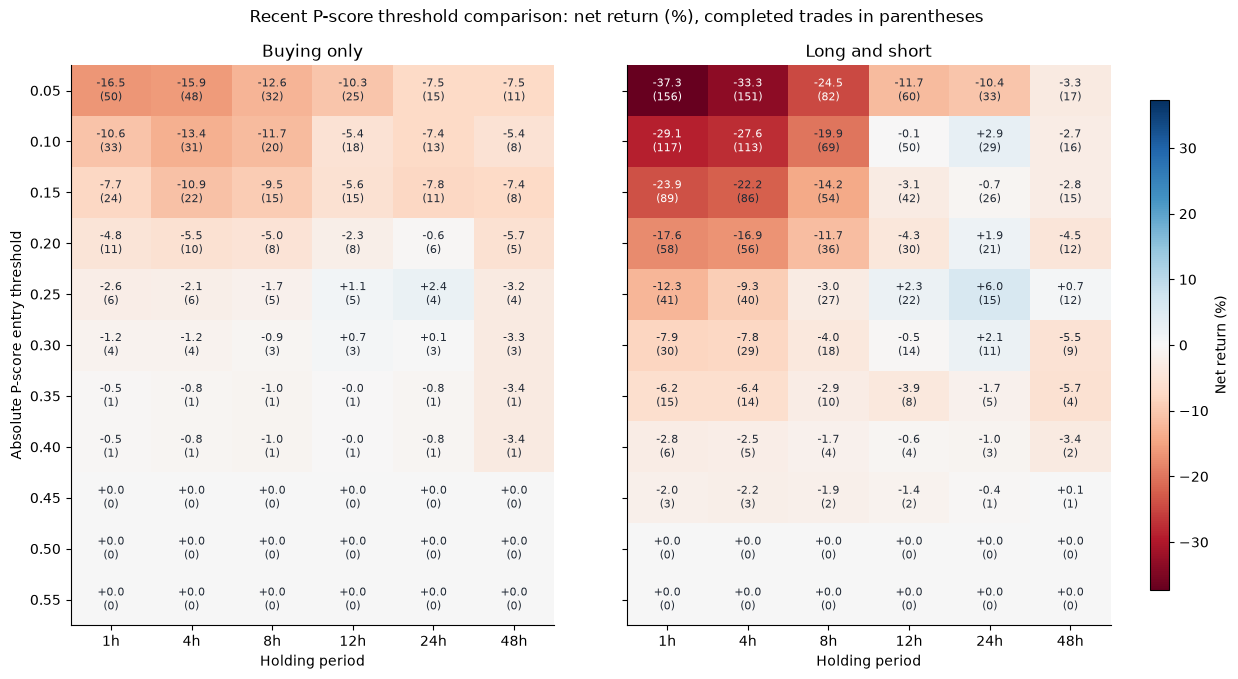

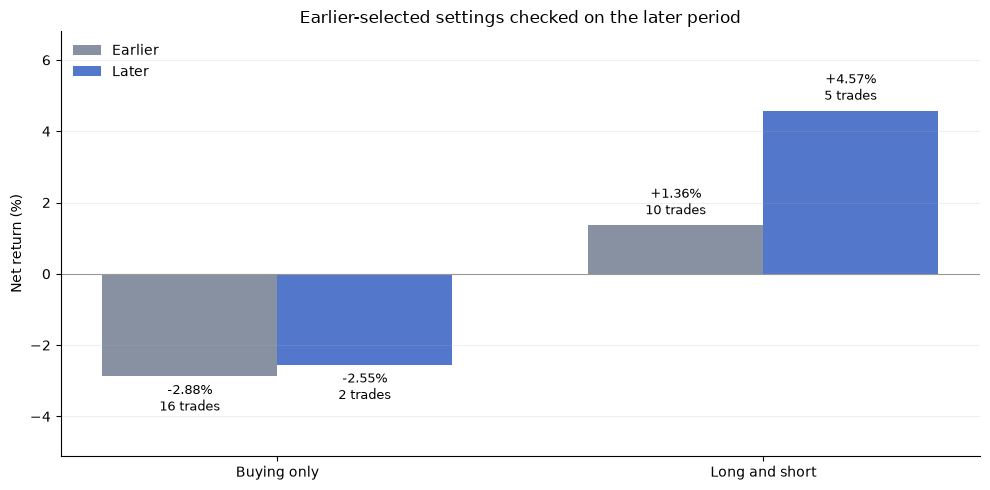

In [9]:
full_grid=threshold_results[threshold_results.segment.eq("Full recent sample")]
limit=float(full_grid.return_pct.abs().max())
fig,axes=plt.subplots(1,2,figsize=(13,7),sharey=True)
for ax,mode in zip(axes,MODES):
    part=full_grid[full_grid["mode"].eq(mode)]
    values=part.pivot(index="threshold",columns="holding_hours",values="return_pct").loc[THRESHOLD_GRID,HOLD_GRID]
    counts=part.pivot(index="threshold",columns="holding_hours",values="trades").loc[THRESHOLD_GRID,HOLD_GRID]
    image=ax.imshow(values,cmap="RdBu",vmin=-limit,vmax=limit,aspect="auto")
    for i in range(len(THRESHOLD_GRID)):
        for j in range(len(HOLD_GRID)):
            value=values.iloc[i,j]
            ax.text(j,i,f"{value:+.1f}\n({counts.iloc[i,j]})",ha="center",va="center",fontsize=8,
                    color="white" if abs(value)>.60*limit else "#202935")
    ax.set_title(mode)
    ax.set_xticks(range(len(HOLD_GRID)),[f"{h}h" for h in HOLD_GRID])
    ax.set_yticks(range(len(THRESHOLD_GRID)),[f"{t:.2f}" for t in THRESHOLD_GRID])
    ax.set_xlabel("Holding period")
axes[0].set_ylabel("Absolute P-score entry threshold")
fig.suptitle("Recent P-score threshold comparison: net return (%), completed trades in parentheses")
fig.subplots_adjust(left=.08,right=.88,top=.9,bottom=.1,wspace=.15)
fig.colorbar(image,cax=fig.add_axes([.91,.15,.015,.7]),label="Net return (%)")
show_chart(fig,"recent_p_threshold_holding_heatmap")

fig,ax=plt.subplots(figsize=(10,5))
x=np.arange(len(MODES))
for offset,segment,color in [(-.18,"Earlier","#8791a1"),(.18,"Later","#5277cb")]:
    rows=chosen_results[chosen_results.segment.eq(segment)].set_index("mode").loc[MODES]
    bars=ax.bar(x+offset,rows.return_pct,width=.36,label=segment,color=color)
    for bar,row in zip(bars,rows.itertuples()):
        ax.annotate(f"{row.return_pct:+.2f}%\n{row.trades} trades",
            xy=(bar.get_x()+bar.get_width()/2,bar.get_height()),xytext=(0,5 if row.return_pct>=0 else -5),
            textcoords="offset points",ha="center",va="bottom" if row.return_pct>=0 else "top",fontsize=9)
ax.set_xticks(x,MODES)
ax.set_ylabel("Net return (%)")
ax.set_title("Earlier-selected settings checked on the later period")
ax.axhline(0,color="#999999",lw=.8)
ax.grid(axis="y",alpha=.2)
ax.legend(frameon=False)
ax.margins(y=.3)
fig.tight_layout()
show_chart(fig,"recent_p_selected_earlier_later")

### Benchmark, price/entry chart and equity

Cash stays at 1,000 USDT. Buy-and-hold enters at each segment's first available entry reference and exits at its last
available hourly open, under the same assumed costs. The strategy equity chart below applies the earlier-selected
long/short setting retrospectively across the full recent sample. The dotted line marks the earlier/later split.
This full-sample curve is not independent validation, and it does not represent a leveraged futures account.

,segment,start_time,end_time,cash_return_pct,buy_hold_return_pct,buy_hold_final_equity
0,Earlier,2026-09-24 21:00:00+00:00,2026-10-22 02:00:00+00:00,0.0,-1.443,985.566
1,Later,2026-10-22 03:00:00+00:00,2026-10-31 14:00:00+00:00,0.0,-6.761,932.388
2,Full recent sample,2026-09-24 21:00:00+00:00,2026-10-31 14:00:00+00:00,0.0,-8.369,916.312


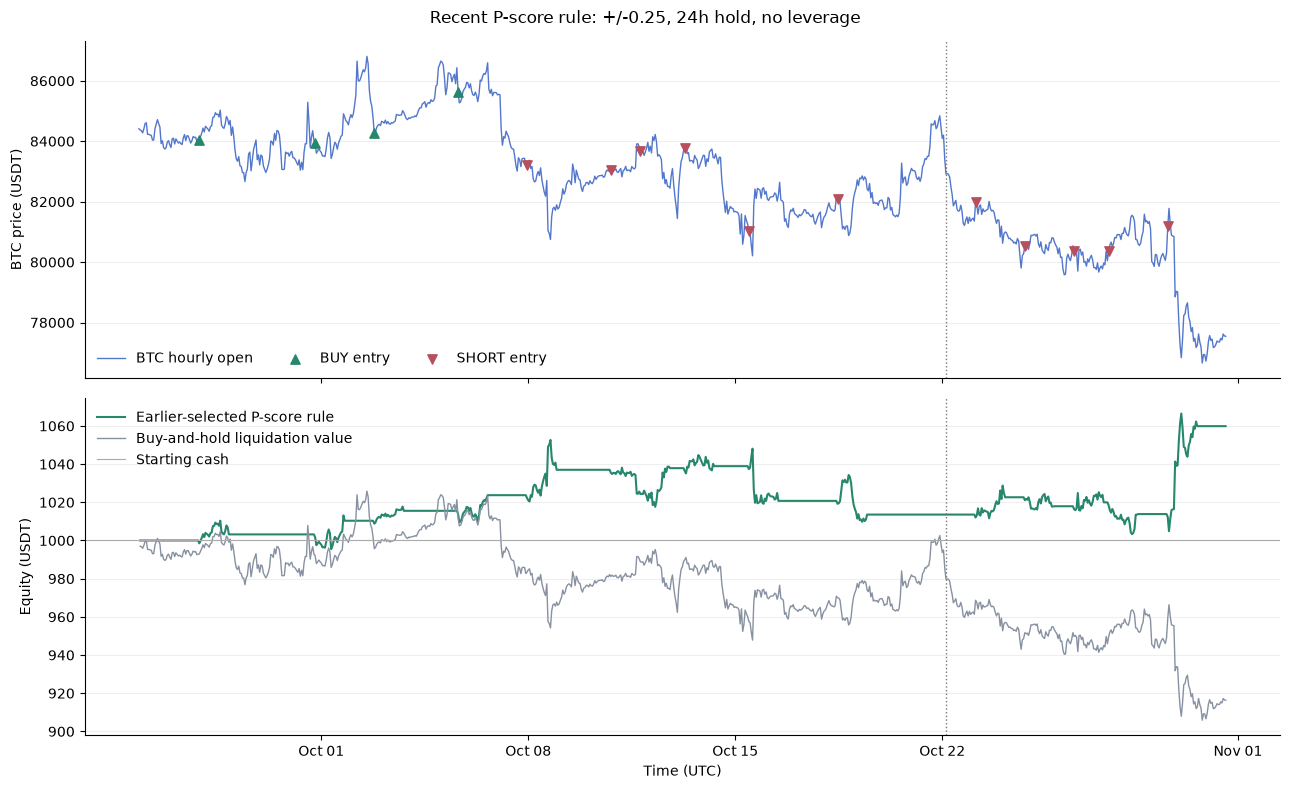

In [10]:
benchmark_rows=[]
for segment,begin,end in SEGMENTS:
    start=signals.entry_time.iloc[begin]
    finish=RECENT_END if end==RECENT_N else signals.timestamp.iloc[end].floor("h")
    units=STARTING_EQUITY/(P.loc[start]*(1+SLIPPAGE_RATE)*(1+FEE_RATE))
    net_final=units*P.loc[finish]*(1-SLIPPAGE_RATE)*(1-FEE_RATE)
    benchmark_rows.append(dict(segment=segment,start_time=str(start),end_time=str(finish),
        cash_return_pct=0.,buy_hold_return_pct=(net_final/STARTING_EQUITY-1)*100,buy_hold_final_equity=net_final))
benchmarks=pd.DataFrame(benchmark_rows)
benchmarks.to_csv(RESULTS_DIR/"recent_p_benchmarks.csv",index=False)
display(benchmarks.round(3))

pick=chosen_settings["Long and short"]
selected_run=simulate_recent_p(pick["threshold"],pick["holding_hours"],"Long and short",0,RECENT_N)
selected_trades=selected_run["trades"]
start=signals.entry_time.iloc[0]
buy_hold_curve=STARTING_EQUITY*P.loc[start:RECENT_END]/P.loc[start]*(1-SLIPPAGE_RATE)*(1-FEE_RATE)/((1+SLIPPAGE_RATE)*(1+FEE_RATE))
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True)
axes[0].plot(P.index,P,color="#5277cb",lw=1,label="BTC hourly open")
for side,label,color,marker in [(1,"BUY entry","#27876c","^"),(-1,"SHORT entry","#b74f5c","v")]:
    t=selected_trades[selected_trades.side.eq(side)]
    axes[0].scatter(t.entry_time,t.entry_open,color=color,marker=marker,s=45,label=label,zorder=4)
axes[0].set_ylabel("BTC price (USDT)")
axes[0].legend(frameon=False,ncol=3)
axes[1].plot(selected_run["equity"].index,selected_run["equity"],color="#27876c",label="Earlier-selected P-score rule")
axes[1].plot(buy_hold_curve.index,buy_hold_curve,color="#8791a1",lw=1,label="Buy-and-hold liquidation value")
axes[1].axhline(STARTING_EQUITY,color="#aaaaaa",lw=.8,label="Starting cash")
axes[1].set_ylabel("Equity (USDT)")
axes[1].set_xlabel("Time (UTC)")
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5,maxticks=8))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
for ax in axes:
    ax.axvline(RECENT_SPLIT,color="#777777",ls=":",lw=1)
    ax.grid(axis="y",alpha=.2)
fig.suptitle(f"Recent P-score rule: +/-{pick['threshold']:.2f}, {pick['holding_hours']}h hold, no leverage")
fig.tight_layout()
show_chart(fig,"recent_p_selected_entries_equity")

### Execution and selection checks

Checks verify forward-only entry timing, non-overlapping positions, capital limits, fee/P&L accounting, drawdown signs,
training-only selection and segment boundaries. Passing checks verifies implementation consistency, not future profitability.

In [11]:
validation=[]
for run in SIMULATIONS.values():
    t=run["trades"]
    if t.empty:
        continue
    assert t.entry_time.gt(t.signal_time).all()
    assert (t.exit_time-t.entry_time).eq(pd.Timedelta(hours=run["metrics"]["holding_hours"])).all()
    assert (t.entry_time.iloc[1:].to_numpy()>=t.exit_time.iloc[:-1].to_numpy()).all()
    assert np.allclose(t.quantity*t.entry_fill*(1+FEE_RATE),t.initial_equity)
    assert np.allclose(t.initial_equity.iloc[1:],t.ending_equity.iloc[:-1])
    independent=t.initial_equity-t.quantity*t.entry_fill*FEE_RATE+t.side*t.quantity*(t.exit_fill-t.entry_fill)-t.quantity*t.exit_fill*FEE_RATE
    assert np.allclose(independent,t.ending_equity)
    assert abs((np.prod(1+t.net_return)-1)*100-run["metrics"]["return_pct"])<1e-8
    assert run["metrics"]["hourly_max_drawdown_pct"]<=1e-8
for mode,choice in chosen_settings.items():
    earlier=simulate_recent_p(choice["threshold"],choice["holding_hours"],mode,0,RECENT_CUT)
    later=simulate_recent_p(choice["threshold"],choice["holding_hours"],mode,RECENT_CUT,RECENT_N)
    assert len(earlier["trades"])>=MIN_TRAINING_TRADES
    assert earlier["trades"].exit_time.lt(RECENT_SPLIT).all()
    assert later["trades"].signal_time.ge(RECENT_SPLIT).all()
    eligible=threshold_results[(threshold_results.segment=="Earlier")&(threshold_results["mode"]==mode)&threshold_results.trades.ge(MIN_TRAINING_TRADES)]
    assert np.isclose(earlier["metrics"]["return_pct"],eligible.return_pct.max())
assert len(threshold_results)==396
assert signals.timestamp.ge(pd.Timestamp("2026-09-01",tz="UTC")).all()
validation=pd.DataFrame([dict(check=name,result="PASS") for name in [
    "Recent data only", "396 mode/threshold/hold/segment results", "Strictly forward entries",
    "Fixed-duration exits", "Non-overlapping positions", "No leverage capital constraint",
    "Independent fee and P&L accounting", "Compounded trade returns", "Earlier-only selection",
    "Segment boundary isolation", "Drawdown signs"]])
display(validation)
validation.to_csv(RESULTS_DIR/"recent_p_threshold_checks.csv",index=False)
threshold_summary=dict(approved_analysis="Recent-only P-score threshold and holding-period comparison",
    observations=RECENT_N,earlier_observations=RECENT_CUT,later_observations=RECENT_N-RECENT_CUT,
    split_utc=str(RECENT_SPLIT),minimum_earlier_trades=MIN_TRAINING_TRADES,
    thresholds=THRESHOLD_GRID,holding_hours=HOLD_GRID,leverage=1,
    fee_per_side=FEE_RATE,slippage_per_side=SLIPPAGE_RATE,
    selected_settings=chosen_settings,
    selected_results=json.loads(chosen_results.to_json(orient="records")),
    benchmarks=json.loads(benchmarks.to_json(orient="records")),checks_passed=len(validation),
    limitations="Previously inspected data; no pristine holdout. No funding, borrowing, margin, liquidation, stop-loss or take-profit model.")
(RESULTS_DIR/"recent_p_threshold_results.json").write_text(json.dumps(threshold_summary,indent=2),encoding="utf-8")
print("Approved P-score threshold study completed. Further analyses await approval.")

,check,result
0,Recent data only,PASS
1,396 mode/threshold/hold/segment results,PASS
2,Strictly forward entries,PASS
3,Fixed-duration exits,PASS
4,Non-overlapping positions,PASS
5,No leverage capital constraint,PASS
6,Independent fee and P&L accounting,PASS
7,Compounded trade returns,PASS
8,Earlier-only selection,PASS
9,Segment boundary isolation,PASS


Approved P-score threshold study completed. Further analyses await approval.


## 8. Approved recent-only threshold and holding-period comparison: news score only

This study changes **only the signal input**, from the combined P-score to the raw news score. It uses the same 192 recent
observations, next-hour entries, one unleveraged position at a time, fees of 0.10% and adverse slippage of 0.05% per side.
The threshold grid (0.05–0.55), holding periods (1, 4, 8, 12, 24 and 48 hours), earlier/later split and minimum of 10 earlier
trades are identical to the approved P-score study.

Buy when the news score reaches the positive threshold; in long/short mode also short at the negative threshold.
The shared engine explicitly reads `news_score` for this chapter. P-score and TA values do not determine these entries.
Original combined scores are retained in ledgers as context, while `signal_score` records the actual news input used.

Choose settings using earlier net returns only; then freeze them for the later period. Full-sample heatmaps remain
exploratory, not selection criteria. The history was already inspected, so the later check is not an untouched holdout.
This remains a hypothetical unleveraged model, without futures funding, borrowing, margin or liquidation mechanics.

In [12]:
def simulate_recent_news(threshold,holding_hours,mode,begin,end):
    return simulate_recent_score("news_score",threshold,holding_hours,mode,begin,end)

In [13]:
news_grid_rows=[]
for segment,begin,end in SEGMENTS:
    for mode in MODES:
        for threshold in THRESHOLD_GRID:
            for hold in HOLD_GRID:
                run=simulate_recent_news(threshold,hold,mode,begin,end)
                news_grid_rows.append(dict(segment=segment,**run["metrics"]))
news_threshold_results=pd.DataFrame(news_grid_rows)
news_threshold_results.to_csv(RESULTS_DIR/"recent_news_threshold_holding_grid.csv",index=False)
news_chosen_settings={}
news_chosen_rows=[]
for mode in MODES:
    eligible=news_threshold_results[(news_threshold_results.segment=="Earlier")&(news_threshold_results["mode"]==mode)&
                                news_threshold_results.trades.ge(MIN_TRAINING_TRADES)]
    if eligible.empty:
        raise ValueError(f"No eligible setting with at least {MIN_TRAINING_TRADES} earlier trades for {mode}.")
    best=eligible.sort_values(["return_pct","trades"],ascending=False).iloc[0]
    news_chosen_settings[mode]={"threshold":float(best.threshold),"holding_hours":int(best.holding_hours)}
    for segment,begin,end in SEGMENTS:
        chosen=simulate_recent_news(float(best.threshold),int(best.holding_hours),mode,begin,end)
        news_chosen_rows.append(dict(segment=segment,**chosen["metrics"]))
        tag=mode.lower().replace(" ","_")+"_"+segment.lower().replace(" ","_")
        chosen["trades"].to_csv(RESULTS_DIR/f"recent_news_selected_{tag}_trades.csv",index=False)
        chosen["equity"].rename("equity").rename_axis("timestamp").to_csv(RESULTS_DIR/f"recent_news_selected_{tag}_equity.csv")
news_chosen_results=pd.DataFrame(news_chosen_rows)
news_chosen_results.to_csv(RESULTS_DIR/"recent_news_training_selected_settings.csv",index=False)
display(pd.DataFrame([dict(mode=mode,**choice) for mode,choice in news_chosen_settings.items()]))
print("Earlier/later boundary (UTC):",RECENT_SPLIT)
display(news_chosen_results[["mode","threshold","holding_hours","segment","trades","longs","shorts",
                        "return_pct","hourly_max_drawdown_pct","win_rate_pct"]].round(3))
print("Win rate is unavailable with no trades; profit factor is unavailable when there are no losses.")

,mode,threshold,holding_hours
0,Buying only,0.15,24
1,Long and short,0.20,48


Earlier/later boundary (UTC): 2026-10-22 02:48:32.320000+00:00


,mode,threshold,holding_hours,segment,trades,longs,shorts,return_pct,hourly_max_drawdown_pct,win_rate_pct
0,Buying only,0.15,24,Earlier,10,10,0,-0.295,-5.326,50.000
1,Buying only,0.15,24,Later,1,1,0,-1.433,-2.203,0.000
2,Buying only,0.15,24,Full recent sample,11,11,0,-4.169,-6.045,45.455
3,Long and short,0.20,48,Earlier,10,4,6,2.711,-4.806,40.000
4,Long and short,0.20,48,Later,4,1,3,-0.832,-4.431,50.000
5,Long and short,0.20,48,Full recent sample,15,6,9,2.452,-8.605,46.667


Win rate is unavailable with no trades; profit factor is unavailable when there are no losses.


### News-only threshold/holding-period landscape

Numbers are full-recent-sample returns after assumed costs. Parentheses show completed trade counts. Settings are
selected from earlier data, not from these full-sample returns. The two trading modes are evaluated separately.

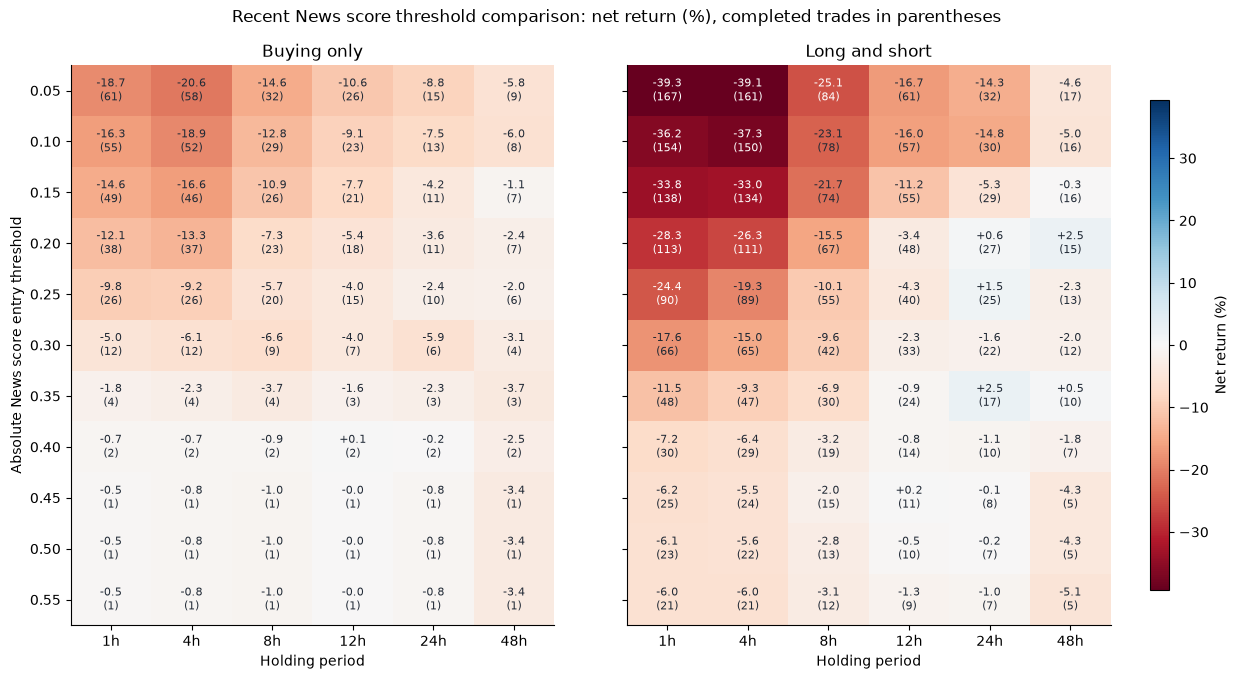

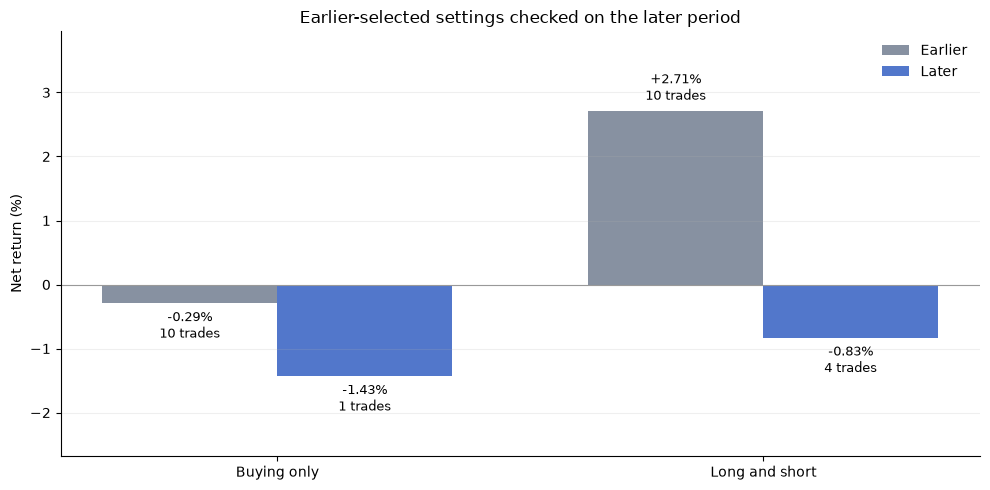

In [14]:
news_full_grid=news_threshold_results[news_threshold_results.segment.eq("Full recent sample")]
limit=float(news_full_grid.return_pct.abs().max())
fig,axes=plt.subplots(1,2,figsize=(13,7),sharey=True)
for ax,mode in zip(axes,MODES):
    part=news_full_grid[news_full_grid["mode"].eq(mode)]
    values=part.pivot(index="threshold",columns="holding_hours",values="return_pct").loc[THRESHOLD_GRID,HOLD_GRID]
    counts=part.pivot(index="threshold",columns="holding_hours",values="trades").loc[THRESHOLD_GRID,HOLD_GRID]
    image=ax.imshow(values,cmap="RdBu",vmin=-limit,vmax=limit,aspect="auto")
    for i in range(len(THRESHOLD_GRID)):
        for j in range(len(HOLD_GRID)):
            value=values.iloc[i,j]
            ax.text(j,i,f"{value:+.1f}\n({counts.iloc[i,j]})",ha="center",va="center",fontsize=8,
                    color="white" if abs(value)>.60*limit else "#202935")
    ax.set_title(mode)
    ax.set_xticks(range(len(HOLD_GRID)),[f"{h}h" for h in HOLD_GRID])
    ax.set_yticks(range(len(THRESHOLD_GRID)),[f"{t:.2f}" for t in THRESHOLD_GRID])
    ax.set_xlabel("Holding period")
axes[0].set_ylabel("Absolute News score entry threshold")
fig.suptitle("Recent News score threshold comparison: net return (%), completed trades in parentheses")
fig.subplots_adjust(left=.08,right=.88,top=.9,bottom=.1,wspace=.15)
fig.colorbar(image,cax=fig.add_axes([.91,.15,.015,.7]),label="Net return (%)")
show_chart(fig,"recent_news_threshold_holding_heatmap")

fig,ax=plt.subplots(figsize=(10,5))
x=np.arange(len(MODES))
for offset,segment,color in [(-.18,"Earlier","#8791a1"),(.18,"Later","#5277cb")]:
    rows=news_chosen_results[news_chosen_results.segment.eq(segment)].set_index("mode").loc[MODES]
    bars=ax.bar(x+offset,rows.return_pct,width=.36,label=segment,color=color)
    for bar,row in zip(bars,rows.itertuples()):
        ax.annotate(f"{row.return_pct:+.2f}%\n{row.trades} trades",
            xy=(bar.get_x()+bar.get_width()/2,bar.get_height()),xytext=(0,5 if row.return_pct>=0 else -5),
            textcoords="offset points",ha="center",va="bottom" if row.return_pct>=0 else "top",fontsize=9)
ax.set_xticks(x,MODES)
ax.set_ylabel("Net return (%)")
ax.set_title("Earlier-selected settings checked on the later period")
ax.axhline(0,color="#999999",lw=.8)
ax.grid(axis="y",alpha=.2)
ax.legend(frameon=False)
ax.margins(y=.3)
fig.tight_layout()
show_chart(fig,"recent_news_selected_earlier_later")

### News-only entries, equity and benchmarks

These charts apply the earlier-selected long/short news rule retrospectively across the full recent period. The dotted
line separates the earlier and later portions. Cash and buy-and-hold are the same benchmarks as in the P-score study.
Trades can differ because news scores have a different distribution and produce different entry times.

,segment,start_time,end_time,cash_return_pct,buy_hold_return_pct,buy_hold_final_equity
0,Earlier,2026-09-24 21:00:00+00:00,2026-10-22 02:00:00+00:00,0.0,-1.443,985.566
1,Later,2026-10-22 03:00:00+00:00,2026-10-31 14:00:00+00:00,0.0,-6.761,932.388
2,Full recent sample,2026-09-24 21:00:00+00:00,2026-10-31 14:00:00+00:00,0.0,-8.369,916.312


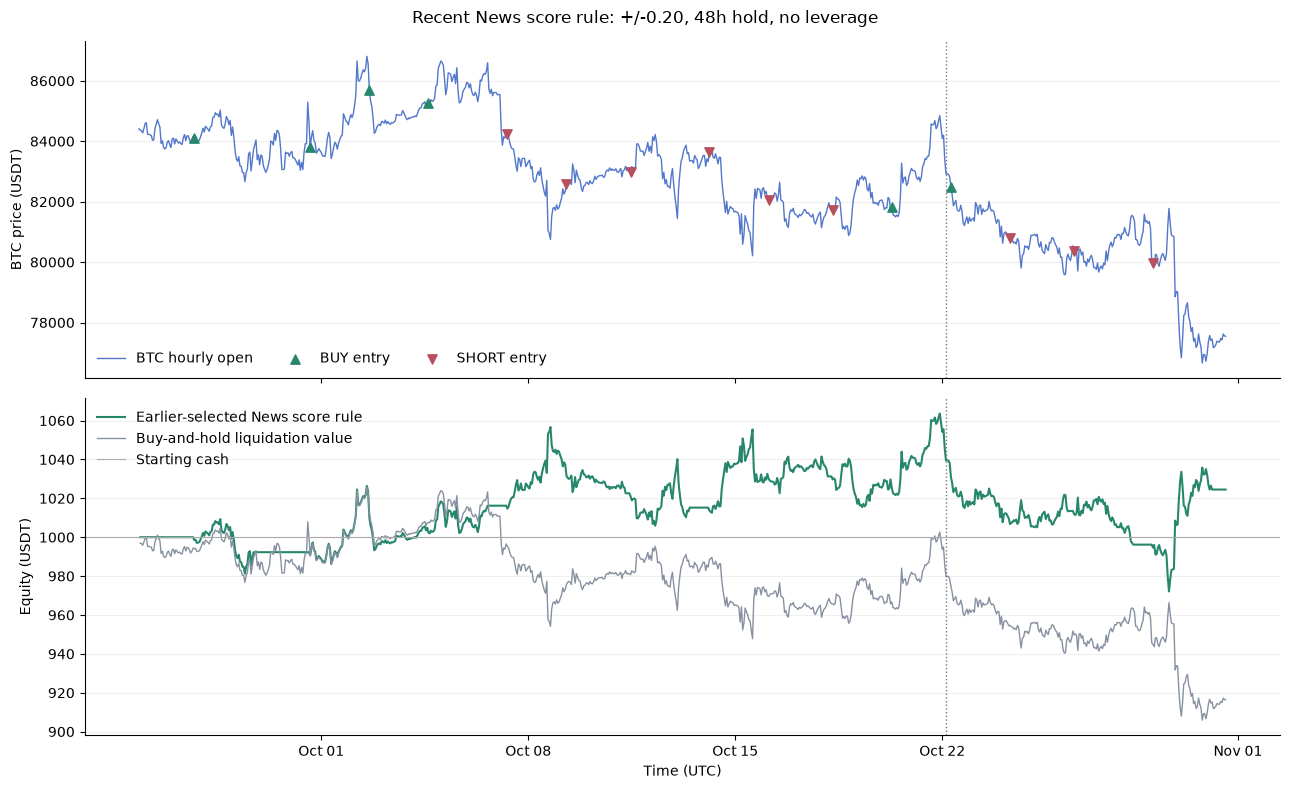

In [15]:
news_benchmark_rows=[]
for segment,begin,end in SEGMENTS:
    start=signals.entry_time.iloc[begin]
    finish=RECENT_END if end==RECENT_N else signals.timestamp.iloc[end].floor("h")
    units=STARTING_EQUITY/(P.loc[start]*(1+SLIPPAGE_RATE)*(1+FEE_RATE))
    net_final=units*P.loc[finish]*(1-SLIPPAGE_RATE)*(1-FEE_RATE)
    news_benchmark_rows.append(dict(segment=segment,start_time=str(start),end_time=str(finish),
        cash_return_pct=0.,buy_hold_return_pct=(net_final/STARTING_EQUITY-1)*100,buy_hold_final_equity=net_final))
news_benchmarks=pd.DataFrame(news_benchmark_rows)
news_benchmarks.to_csv(RESULTS_DIR/"recent_news_benchmarks.csv",index=False)
display(news_benchmarks.round(3))

pick=news_chosen_settings["Long and short"]
news_selected_run=simulate_recent_news(pick["threshold"],pick["holding_hours"],"Long and short",0,RECENT_N)
news_selected_trades=news_selected_run["trades"]
start=signals.entry_time.iloc[0]
buy_hold_curve=STARTING_EQUITY*P.loc[start:RECENT_END]/P.loc[start]*(1-SLIPPAGE_RATE)*(1-FEE_RATE)/((1+SLIPPAGE_RATE)*(1+FEE_RATE))
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True)
axes[0].plot(P.index,P,color="#5277cb",lw=1,label="BTC hourly open")
for side,label,color,marker in [(1,"BUY entry","#27876c","^"),(-1,"SHORT entry","#b74f5c","v")]:
    t=news_selected_trades[news_selected_trades.side.eq(side)]
    axes[0].scatter(t.entry_time,t.entry_open,color=color,marker=marker,s=45,label=label,zorder=4)
axes[0].set_ylabel("BTC price (USDT)")
axes[0].legend(frameon=False,ncol=3)
axes[1].plot(news_selected_run["equity"].index,news_selected_run["equity"],color="#27876c",label="Earlier-selected News score rule")
axes[1].plot(buy_hold_curve.index,buy_hold_curve,color="#8791a1",lw=1,label="Buy-and-hold liquidation value")
axes[1].axhline(STARTING_EQUITY,color="#aaaaaa",lw=.8,label="Starting cash")
axes[1].set_ylabel("Equity (USDT)")
axes[1].set_xlabel("Time (UTC)")
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5,maxticks=8))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
for ax in axes:
    ax.axvline(RECENT_SPLIT,color="#777777",ls=":",lw=1)
    ax.grid(axis="y",alpha=.2)
fig.suptitle(f"Recent News score rule: +/-{pick['threshold']:.2f}, {pick['holding_hours']}h hold, no leverage")
fig.tight_layout()
show_chart(fig,"recent_news_selected_entries_equity")

### News-only execution checks and comparison with the approved P-score results

The shared engine must reproduce the previous P-score results unchanged. News-only ledgers must use actual news
scores and satisfy the chosen side's threshold. These checks supplement the timing, accounting and selection checks.

In [16]:
news_validation=[]
for run in SIMULATIONS.values():
    t=run["trades"]
    if t.empty:
        continue
    assert t.entry_time.gt(t.signal_time).all()
    assert (t.exit_time-t.entry_time).eq(pd.Timedelta(hours=run["metrics"]["holding_hours"])).all()
    assert (t.entry_time.iloc[1:].to_numpy()>=t.exit_time.iloc[:-1].to_numpy()).all()
    assert np.allclose(t.quantity*t.entry_fill*(1+FEE_RATE),t.initial_equity)
    assert np.allclose(t.initial_equity.iloc[1:],t.ending_equity.iloc[:-1])
    independent=t.initial_equity-t.quantity*t.entry_fill*FEE_RATE+t.side*t.quantity*(t.exit_fill-t.entry_fill)-t.quantity*t.exit_fill*FEE_RATE
    assert np.allclose(independent,t.ending_equity)
    assert abs((np.prod(1+t.net_return)-1)*100-run["metrics"]["return_pct"])<1e-8
    assert run["metrics"]["hourly_max_drawdown_pct"]<=1e-8
for mode,choice in news_chosen_settings.items():
    earlier=simulate_recent_news(choice["threshold"],choice["holding_hours"],mode,0,RECENT_CUT)
    later=simulate_recent_news(choice["threshold"],choice["holding_hours"],mode,RECENT_CUT,RECENT_N)
    assert len(earlier["trades"])>=MIN_TRAINING_TRADES
    assert earlier["trades"].exit_time.lt(RECENT_SPLIT).all()
    assert later["trades"].signal_time.ge(RECENT_SPLIT).all()
    eligible=news_threshold_results[(news_threshold_results.segment=="Earlier")&(news_threshold_results["mode"]==mode)&news_threshold_results.trades.ge(MIN_TRAINING_TRADES)]
    assert np.isclose(earlier["metrics"]["return_pct"],eligible.return_pct.max())
assert len(news_threshold_results)==396
assert signals.timestamp.ge(pd.Timestamp("2026-09-01",tz="UTC")).all()
news_validation=pd.DataFrame([dict(check=name,result="PASS") for name in [
    "Recent data only", "396 mode/threshold/hold/segment results", "Strictly forward entries",
    "Fixed-duration exits", "Non-overlapping positions", "No leverage capital constraint",
    "Independent fee and P&L accounting", "Compounded trade returns", "Earlier-only selection",
    "Segment boundary isolation", "Drawdown signs"]])
display(news_validation)
news_validation.to_csv(RESULTS_DIR/"recent_news_threshold_checks.csv",index=False)
news_threshold_summary=dict(approved_analysis="Recent-only News score threshold and holding-period comparison",
    observations=RECENT_N,earlier_observations=RECENT_CUT,later_observations=RECENT_N-RECENT_CUT,
    split_utc=str(RECENT_SPLIT),minimum_earlier_trades=MIN_TRAINING_TRADES,
    thresholds=THRESHOLD_GRID,holding_hours=HOLD_GRID,leverage=1,
    fee_per_side=FEE_RATE,slippage_per_side=SLIPPAGE_RATE,
    selected_settings=news_chosen_settings,
    selected_results=json.loads(news_chosen_results.to_json(orient="records")),
    news_benchmarks=json.loads(news_benchmarks.to_json(orient="records")),checks_passed=len(news_validation),
    limitations="Previously inspected data; no pristine holdout. No funding, borrowing, margin, liquidation, stop-loss or take-profit model.")
(RESULTS_DIR/"recent_news_threshold_results.json").write_text(json.dumps(news_threshold_summary,indent=2),encoding="utf-8")
print("Approved News score threshold study completed. Further analyses await approval.")

,check,result
0,Recent data only,PASS
1,396 mode/threshold/hold/segment results,PASS
2,Strictly forward entries,PASS
3,Fixed-duration exits,PASS
4,Non-overlapping positions,PASS
5,No leverage capital constraint,PASS
6,Independent fee and P&L accounting,PASS
7,Compounded trade returns,PASS
8,Earlier-only selection,PASS
9,Segment boundary isolation,PASS


Approved News score threshold study completed. Further analyses await approval.


In [17]:
for mode,choice in news_chosen_settings.items():
    for segment,begin,end in SEGMENTS:
        t=simulate_recent_news(choice["threshold"],choice["holding_hours"],mode,begin,end)["trades"]
        if t.empty:
            continue
        assert t.score_column.eq("news_score").all()
        assert np.allclose(t.signal_score.to_numpy(),signals.news_score.iloc[t.source_row.astype(int)].to_numpy())
        assert t.loc[t.side.eq(1),"signal_score"].ge(choice["threshold"]).all()
        assert t.loc[t.side.eq(-1),"signal_score"].le(-choice["threshold"]).all()

approved_signal_comparison=pd.concat([
    chosen_results.assign(signal="70/30 P-score"),
    news_chosen_results.assign(signal="News score only")
],ignore_index=True)
display(approved_signal_comparison[["signal","mode","threshold","holding_hours","segment","trades",
                                  "return_pct","hourly_max_drawdown_pct","win_rate_pct"]].round(3))
approved_signal_comparison.to_csv(RESULTS_DIR/"recent_p_vs_news_selected_settings.csv",index=False)
print("News-only study complete. TA-only trading tests still await approval.")

,signal,mode,threshold,holding_hours,segment,trades,return_pct,hourly_max_drawdown_pct,win_rate_pct
0,70/30 P-score,Buying only,0.10,12,Earlier,16,-2.876,-6.904,50.000
1,70/30 P-score,Buying only,0.10,12,Later,2,-2.552,-2.552,0.000
2,70/30 P-score,Buying only,0.10,12,Full recent sample,18,-5.354,-6.904,44.444
3,70/30 P-score,Long and short,0.25,24,Earlier,10,1.357,-4.073,70.000
4,70/30 P-score,Long and short,0.25,24,Later,5,4.569,-2.471,60.000
5,70/30 P-score,Long and short,0.25,24,Full recent sample,15,5.988,-4.688,66.667
6,News score only,Buying only,0.15,24,Earlier,10,-0.295,-5.326,50.000
7,News score only,Buying only,0.15,24,Later,1,-1.433,-2.203,0.000
8,News score only,Buying only,0.15,24,Full recent sample,11,-4.169,-6.045,45.455
9,News score only,Long and short,0.20,48,Earlier,10,2.711,-4.806,40.000


News-only study complete. TA-only trading tests still await approval.


## 9. Approved recent-only threshold and holding-period comparison: technical score only

This study changes **only the signal input** to the raw technical (`ta_score`) feature. The score comes from the existing
RSI/support-and-resistance analysis; no indicators are recalculated or modified. News and combined P-scores do not determine
these entries. HOLD remains a placeholder.

The same execution rules and grid are used: 192 September–October observations; thresholds 0.05–0.55; holds of
1, 4, 8, 12, 24 and 48 hours; next-hour entries; one position at a time; no leverage; 0.10% fees and 0.05% adverse slippage
per side. Choose each trading mode's pair using earlier net returns, requiring at least 10 earlier completed trades, then
freeze that pair for the later check. The actual TA range is verified below; a 0.55 cutoff should produce no trades.

This is still a simplified hypothetical short-exposure model without funding, borrowing, margin or liquidation rules.
No stop-loss or take-profit levels are inferred. The already-viewed later period is not a pristine untouched holdout.

In [18]:
def simulate_recent_ta(threshold,holding_hours,mode,begin,end):
    return simulate_recent_score("ta_score",threshold,holding_hours,mode,begin,end)

In [19]:
ta_grid_rows=[]
for segment,begin,end in SEGMENTS:
    for mode in MODES:
        for threshold in THRESHOLD_GRID:
            for hold in HOLD_GRID:
                run=simulate_recent_ta(threshold,hold,mode,begin,end)
                ta_grid_rows.append(dict(segment=segment,**run["metrics"]))
ta_threshold_results=pd.DataFrame(ta_grid_rows)
ta_threshold_results.to_csv(RESULTS_DIR/"recent_ta_threshold_holding_grid.csv",index=False)
ta_chosen_settings={}
ta_chosen_rows=[]
for mode in MODES:
    eligible=ta_threshold_results[(ta_threshold_results.segment=="Earlier")&(ta_threshold_results["mode"]==mode)&
                                ta_threshold_results.trades.ge(MIN_TRAINING_TRADES)]
    if eligible.empty:
        raise ValueError(f"No eligible setting with at least {MIN_TRAINING_TRADES} earlier trades for {mode}.")
    best=eligible.sort_values(["return_pct","trades"],ascending=False).iloc[0]
    ta_chosen_settings[mode]={"threshold":float(best.threshold),"holding_hours":int(best.holding_hours)}
    for segment,begin,end in SEGMENTS:
        chosen=simulate_recent_ta(float(best.threshold),int(best.holding_hours),mode,begin,end)
        ta_chosen_rows.append(dict(segment=segment,**chosen["metrics"]))
        tag=mode.lower().replace(" ","_")+"_"+segment.lower().replace(" ","_")
        chosen["trades"].to_csv(RESULTS_DIR/f"recent_ta_selected_{tag}_trades.csv",index=False)
        chosen["equity"].rename("equity").rename_axis("timestamp").to_csv(RESULTS_DIR/f"recent_ta_selected_{tag}_equity.csv")
ta_chosen_results=pd.DataFrame(ta_chosen_rows)
ta_chosen_results.to_csv(RESULTS_DIR/"recent_ta_training_selected_settings.csv",index=False)
display(pd.DataFrame([dict(mode=mode,**choice) for mode,choice in ta_chosen_settings.items()]))
print("Earlier/later boundary (UTC):",RECENT_SPLIT)
display(ta_chosen_results[["mode","threshold","holding_hours","segment","trades","longs","shorts",
                        "return_pct","hourly_max_drawdown_pct","win_rate_pct"]].round(3))
print("Win rate is unavailable with no trades; profit factor is unavailable when there are no losses.")

,mode,threshold,holding_hours
0,Buying only,0.15,24
1,Long and short,0.35,24


Earlier/later boundary (UTC): 2026-10-22 02:48:32.320000+00:00


,mode,threshold,holding_hours,segment,trades,longs,shorts,return_pct,hourly_max_drawdown_pct,win_rate_pct
0,Buying only,0.15,24,Earlier,13,13,0,-1.066,-6.122,61.538
1,Buying only,0.15,24,Later,7,7,0,-6.296,-7.114,28.571
2,Buying only,0.15,24,Full recent sample,20,20,0,-7.295,-9.192,50.000
3,Long and short,0.35,24,Earlier,11,5,6,-0.164,-6.335,63.636
4,Long and short,0.35,24,Later,5,4,1,-4.659,-4.905,0.000
5,Long and short,0.35,24,Full recent sample,17,9,8,-1.690,-6.335,47.059


Win rate is unavailable with no trades; profit factor is unavailable when there are no losses.


### TA-only threshold/holding-period landscape

The heatmaps show exploratory full-recent-sample net returns after costs, with completed-trade counts in parentheses.
They are not used to choose the earlier-period settings. Sparse cells with high returns are not independent evidence of an edge.

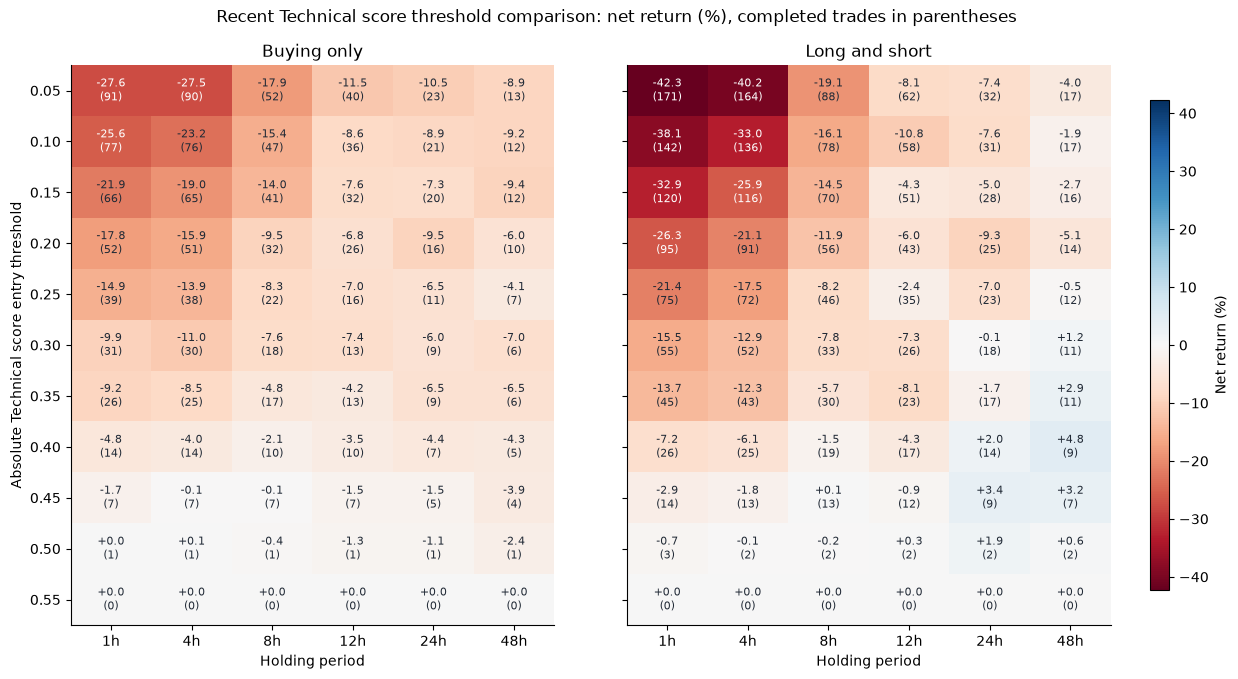

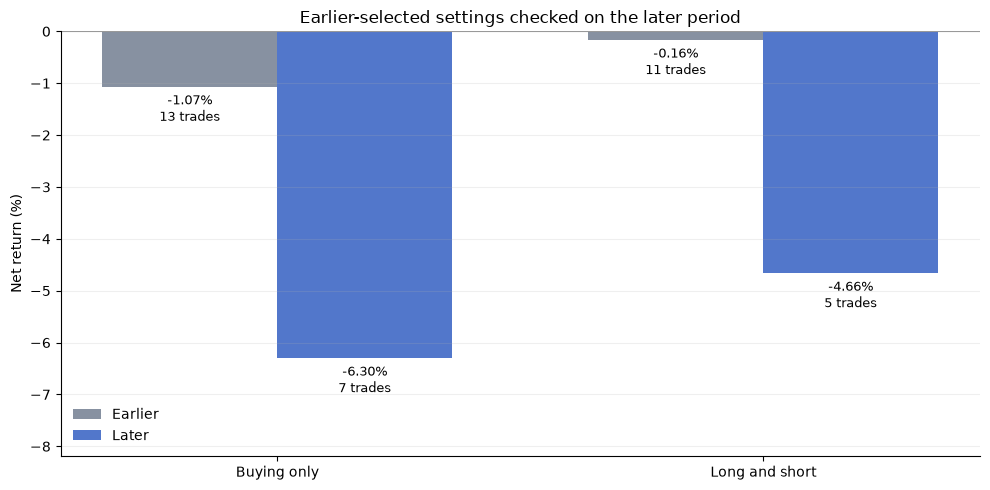

In [20]:
ta_full_grid=ta_threshold_results[ta_threshold_results.segment.eq("Full recent sample")]
limit=float(ta_full_grid.return_pct.abs().max())
fig,axes=plt.subplots(1,2,figsize=(13,7),sharey=True)
for ax,mode in zip(axes,MODES):
    part=ta_full_grid[ta_full_grid["mode"].eq(mode)]
    values=part.pivot(index="threshold",columns="holding_hours",values="return_pct").loc[THRESHOLD_GRID,HOLD_GRID]
    counts=part.pivot(index="threshold",columns="holding_hours",values="trades").loc[THRESHOLD_GRID,HOLD_GRID]
    image=ax.imshow(values,cmap="RdBu",vmin=-limit,vmax=limit,aspect="auto")
    for i in range(len(THRESHOLD_GRID)):
        for j in range(len(HOLD_GRID)):
            value=values.iloc[i,j]
            ax.text(j,i,f"{value:+.1f}\n({counts.iloc[i,j]})",ha="center",va="center",fontsize=8,
                    color="white" if abs(value)>.60*limit else "#202935")
    ax.set_title(mode)
    ax.set_xticks(range(len(HOLD_GRID)),[f"{h}h" for h in HOLD_GRID])
    ax.set_yticks(range(len(THRESHOLD_GRID)),[f"{t:.2f}" for t in THRESHOLD_GRID])
    ax.set_xlabel("Holding period")
axes[0].set_ylabel("Absolute Technical score entry threshold")
fig.suptitle("Recent Technical score threshold comparison: net return (%), completed trades in parentheses")
fig.subplots_adjust(left=.08,right=.88,top=.9,bottom=.1,wspace=.15)
fig.colorbar(image,cax=fig.add_axes([.91,.15,.015,.7]),label="Net return (%)")
show_chart(fig,"recent_ta_threshold_holding_heatmap")

fig,ax=plt.subplots(figsize=(10,5))
x=np.arange(len(MODES))
for offset,segment,color in [(-.18,"Earlier","#8791a1"),(.18,"Later","#5277cb")]:
    rows=ta_chosen_results[ta_chosen_results.segment.eq(segment)].set_index("mode").loc[MODES]
    bars=ax.bar(x+offset,rows.return_pct,width=.36,label=segment,color=color)
    for bar,row in zip(bars,rows.itertuples()):
        ax.annotate(f"{row.return_pct:+.2f}%\n{row.trades} trades",
            xy=(bar.get_x()+bar.get_width()/2,bar.get_height()),xytext=(0,5 if row.return_pct>=0 else -5),
            textcoords="offset points",ha="center",va="bottom" if row.return_pct>=0 else "top",fontsize=9)
ax.set_xticks(x,MODES)
ax.set_ylabel("Net return (%)")
ax.set_title("Earlier-selected settings checked on the later period")
ax.axhline(0,color="#999999",lw=.8)
ax.grid(axis="y",alpha=.2)
ax.legend(frameon=False)
ax.margins(y=.3)
fig.tight_layout()
show_chart(fig,"recent_ta_selected_earlier_later")

### TA-only entries, equity and benchmarks

The earlier-selected long/short technical rule is applied retrospectively across the full recent period for this chart.
The dotted line separates earlier and later observations. The cost-adjusted cash and buy-and-hold benchmarks are
the same as those in the P-score and news-only chapters.

,segment,start_time,end_time,cash_return_pct,buy_hold_return_pct,buy_hold_final_equity
0,Earlier,2026-09-24 21:00:00+00:00,2026-10-22 02:00:00+00:00,0.0,-1.443,985.566
1,Later,2026-10-22 03:00:00+00:00,2026-10-31 14:00:00+00:00,0.0,-6.761,932.388
2,Full recent sample,2026-09-24 21:00:00+00:00,2026-10-31 14:00:00+00:00,0.0,-8.369,916.312


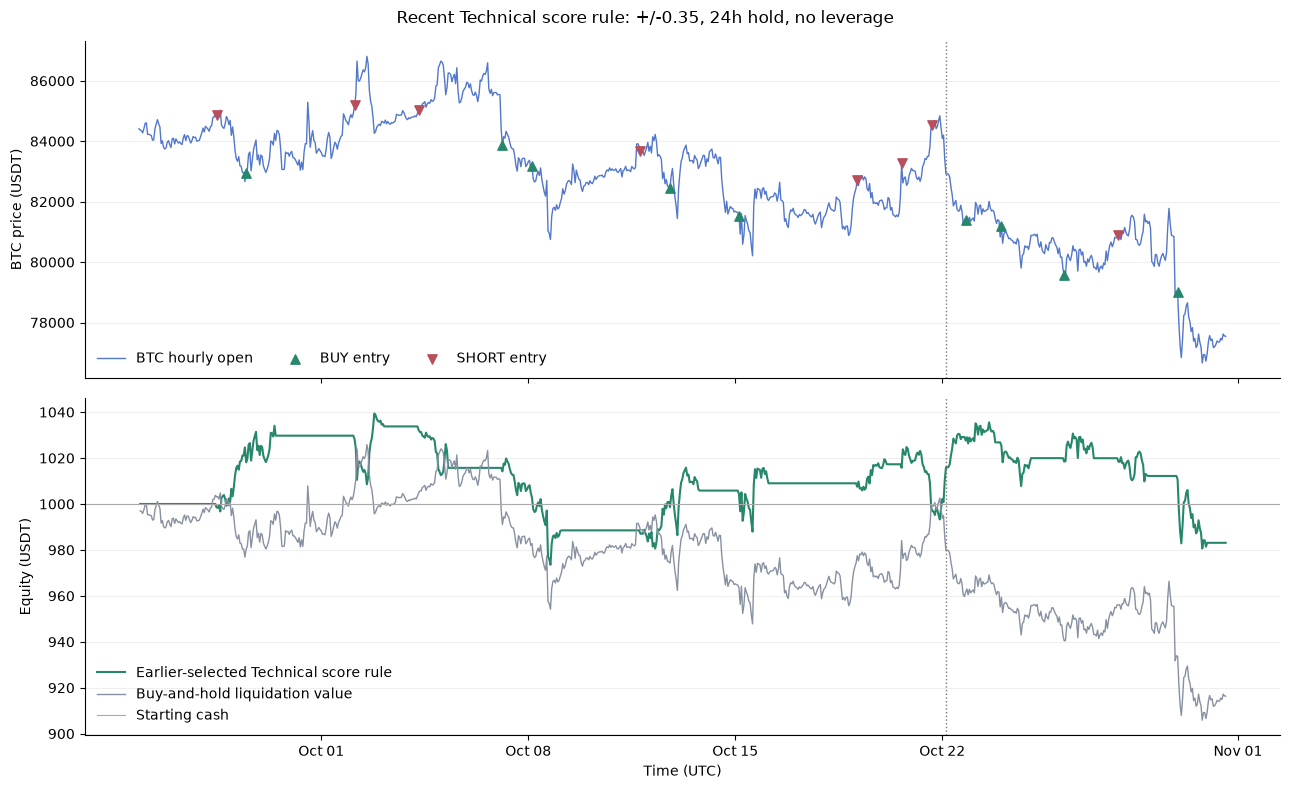

In [21]:
ta_benchmark_rows=[]
for segment,begin,end in SEGMENTS:
    start=signals.entry_time.iloc[begin]
    finish=RECENT_END if end==RECENT_N else signals.timestamp.iloc[end].floor("h")
    units=STARTING_EQUITY/(P.loc[start]*(1+SLIPPAGE_RATE)*(1+FEE_RATE))
    net_final=units*P.loc[finish]*(1-SLIPPAGE_RATE)*(1-FEE_RATE)
    ta_benchmark_rows.append(dict(segment=segment,start_time=str(start),end_time=str(finish),
        cash_return_pct=0.,buy_hold_return_pct=(net_final/STARTING_EQUITY-1)*100,buy_hold_final_equity=net_final))
ta_benchmarks=pd.DataFrame(ta_benchmark_rows)
ta_benchmarks.to_csv(RESULTS_DIR/"recent_ta_benchmarks.csv",index=False)
display(ta_benchmarks.round(3))

pick=ta_chosen_settings["Long and short"]
ta_selected_run=simulate_recent_ta(pick["threshold"],pick["holding_hours"],"Long and short",0,RECENT_N)
ta_selected_trades=ta_selected_run["trades"]
start=signals.entry_time.iloc[0]
buy_hold_curve=STARTING_EQUITY*P.loc[start:RECENT_END]/P.loc[start]*(1-SLIPPAGE_RATE)*(1-FEE_RATE)/((1+SLIPPAGE_RATE)*(1+FEE_RATE))
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True)
axes[0].plot(P.index,P,color="#5277cb",lw=1,label="BTC hourly open")
for side,label,color,marker in [(1,"BUY entry","#27876c","^"),(-1,"SHORT entry","#b74f5c","v")]:
    t=ta_selected_trades[ta_selected_trades.side.eq(side)]
    axes[0].scatter(t.entry_time,t.entry_open,color=color,marker=marker,s=45,label=label,zorder=4)
axes[0].set_ylabel("BTC price (USDT)")
axes[0].legend(frameon=False,ncol=3)
axes[1].plot(ta_selected_run["equity"].index,ta_selected_run["equity"],color="#27876c",label="Earlier-selected Technical score rule")
axes[1].plot(buy_hold_curve.index,buy_hold_curve,color="#8791a1",lw=1,label="Buy-and-hold liquidation value")
axes[1].axhline(STARTING_EQUITY,color="#aaaaaa",lw=.8,label="Starting cash")
axes[1].set_ylabel("Equity (USDT)")
axes[1].set_xlabel("Time (UTC)")
axes[1].legend(frameon=False)
axes[1].xaxis.set_major_locator(mdates.AutoDateLocator(minticks=5,maxticks=8))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
for ax in axes:
    ax.axvline(RECENT_SPLIT,color="#777777",ls=":",lw=1)
    ax.grid(axis="y",alpha=.2)
fig.suptitle(f"Recent Technical score rule: +/-{pick['threshold']:.2f}, {pick['holding_hours']}h hold, no leverage")
fig.tight_layout()
show_chart(fig,"recent_ta_selected_entries_equity")

### Execution checks and comparison of the three approved signal inputs

All three models use the same engine, input dates, costs, account rules, parameter search and chronological split.
Each selects its own threshold/holding pair using the earlier data; the selected pairs can therefore differ.
The comparison is descriptive and is not a statistical test of superiority on this small, repeatedly explored dataset.

Full-sample returns need not equal the product of the earlier and later returns. Segmented checks exclude trades that cross the split, and skipping those positions can change which subsequent entries are available.

In [22]:
ta_validation=[]
for run in SIMULATIONS.values():
    t=run["trades"]
    if t.empty:
        continue
    assert t.entry_time.gt(t.signal_time).all()
    assert (t.exit_time-t.entry_time).eq(pd.Timedelta(hours=run["metrics"]["holding_hours"])).all()
    assert (t.entry_time.iloc[1:].to_numpy()>=t.exit_time.iloc[:-1].to_numpy()).all()
    assert np.allclose(t.quantity*t.entry_fill*(1+FEE_RATE),t.initial_equity)
    assert np.allclose(t.initial_equity.iloc[1:],t.ending_equity.iloc[:-1])
    independent=t.initial_equity-t.quantity*t.entry_fill*FEE_RATE+t.side*t.quantity*(t.exit_fill-t.entry_fill)-t.quantity*t.exit_fill*FEE_RATE
    assert np.allclose(independent,t.ending_equity)
    assert abs((np.prod(1+t.net_return)-1)*100-run["metrics"]["return_pct"])<1e-8
    assert run["metrics"]["hourly_max_drawdown_pct"]<=1e-8
for mode,choice in ta_chosen_settings.items():
    earlier=simulate_recent_ta(choice["threshold"],choice["holding_hours"],mode,0,RECENT_CUT)
    later=simulate_recent_ta(choice["threshold"],choice["holding_hours"],mode,RECENT_CUT,RECENT_N)
    assert len(earlier["trades"])>=MIN_TRAINING_TRADES
    assert earlier["trades"].exit_time.lt(RECENT_SPLIT).all()
    assert later["trades"].signal_time.ge(RECENT_SPLIT).all()
    eligible=ta_threshold_results[(ta_threshold_results.segment=="Earlier")&(ta_threshold_results["mode"]==mode)&ta_threshold_results.trades.ge(MIN_TRAINING_TRADES)]
    assert np.isclose(earlier["metrics"]["return_pct"],eligible.return_pct.max())
assert len(ta_threshold_results)==396
assert signals.timestamp.ge(pd.Timestamp("2026-09-01",tz="UTC")).all()
ta_validation=pd.DataFrame([dict(check=name,result="PASS") for name in [
    "Recent data only", "396 mode/threshold/hold/segment results", "Strictly forward entries",
    "Fixed-duration exits", "Non-overlapping positions", "No leverage capital constraint",
    "Independent fee and P&L accounting", "Compounded trade returns", "Earlier-only selection",
    "Segment boundary isolation", "Drawdown signs"]])
display(ta_validation)
ta_validation.to_csv(RESULTS_DIR/"recent_ta_threshold_checks.csv",index=False)
ta_threshold_summary=dict(approved_analysis="Recent-only Technical score threshold and holding-period comparison",
    observations=RECENT_N,earlier_observations=RECENT_CUT,later_observations=RECENT_N-RECENT_CUT,
    split_utc=str(RECENT_SPLIT),minimum_earlier_trades=MIN_TRAINING_TRADES,
    thresholds=THRESHOLD_GRID,holding_hours=HOLD_GRID,leverage=1,
    fee_per_side=FEE_RATE,slippage_per_side=SLIPPAGE_RATE,
    selected_settings=ta_chosen_settings,
    selected_results=json.loads(ta_chosen_results.to_json(orient="records")),
    ta_benchmarks=json.loads(ta_benchmarks.to_json(orient="records")),checks_passed=len(ta_validation),
    limitations="Previously inspected data; no pristine holdout. No funding, borrowing, margin, liquidation, stop-loss or take-profit model.")
(RESULTS_DIR/"recent_ta_threshold_results.json").write_text(json.dumps(ta_threshold_summary,indent=2),encoding="utf-8")
print("Approved Technical score threshold study completed. Further analyses await approval.")

,check,result
0,Recent data only,PASS
1,396 mode/threshold/hold/segment results,PASS
2,Strictly forward entries,PASS
3,Fixed-duration exits,PASS
4,Non-overlapping positions,PASS
5,No leverage capital constraint,PASS
6,Independent fee and P&L accounting,PASS
7,Compounded trade returns,PASS
8,Earlier-only selection,PASS
9,Segment boundary isolation,PASS


Approved Technical score threshold study completed. Further analyses await approval.


,signal,mode,threshold,holding_hours,segment,trades,return_pct,hourly_max_drawdown_pct,win_rate_pct
0,70/30 P-score,Buying only,0.10,12,Earlier,16,-2.876,-6.904,50.000
1,70/30 P-score,Buying only,0.10,12,Later,2,-2.552,-2.552,0.000
2,70/30 P-score,Buying only,0.10,12,Full recent sample,18,-5.354,-6.904,44.444
3,70/30 P-score,Long and short,0.25,24,Earlier,10,1.357,-4.073,70.000
4,70/30 P-score,Long and short,0.25,24,Later,5,4.569,-2.471,60.000
5,70/30 P-score,Long and short,0.25,24,Full recent sample,15,5.988,-4.688,66.667
6,News score only,Buying only,0.15,24,Earlier,10,-0.295,-5.326,50.000
7,News score only,Buying only,0.15,24,Later,1,-1.433,-2.203,0.000
8,News score only,Buying only,0.15,24,Full recent sample,11,-4.169,-6.045,45.455
9,News score only,Long and short,0.20,48,Earlier,10,2.711,-4.806,40.000


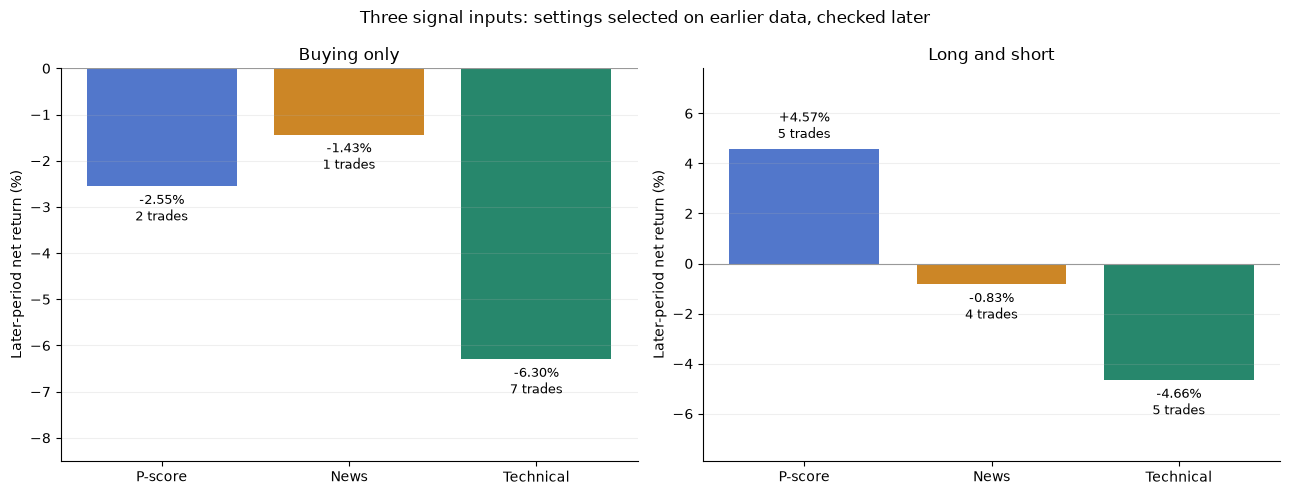

TA-only study complete. All further analyses require separate approval.


In [23]:
for mode,choice in ta_chosen_settings.items():
    for segment,begin,end in SEGMENTS:
        t=simulate_recent_ta(choice["threshold"],choice["holding_hours"],mode,begin,end)["trades"]
        if t.empty:
            continue
        assert t.score_column.eq("ta_score").all()
        assert np.allclose(t.signal_score.to_numpy(),signals.ta_score.iloc[t.source_row.astype(int)].to_numpy())
        assert t.loc[t.side.eq(1),"signal_score"].ge(choice["threshold"]).all()
        assert t.loc[t.side.eq(-1),"signal_score"].le(-choice["threshold"]).all()



assert signals.ta_score.between(-.5,.5).all()
assert ta_threshold_results.loc[ta_threshold_results.threshold.eq(.55),"trades"].eq(0).all()
three_signal_comparison=pd.concat([
    chosen_results.assign(signal="70/30 P-score"),
    news_chosen_results.assign(signal="News score only"),
    ta_chosen_results.assign(signal="Technical score only")
],ignore_index=True)
display(three_signal_comparison[["signal","mode","threshold","holding_hours","segment","trades",
                               "return_pct","hourly_max_drawdown_pct","win_rate_pct"]].round(3))
three_signal_comparison.to_csv(RESULTS_DIR/"recent_p_vs_news_vs_ta_selected_settings.csv",index=False)
later_three=three_signal_comparison[three_signal_comparison.segment.eq("Later")]
fig,axes=plt.subplots(1,2,figsize=(13,5))
for ax,mode in zip(axes,MODES):
    part=later_three[later_three["mode"].eq(mode)]
    bars=ax.bar(["P-score","News","Technical"],part.return_pct,
                color=["#5277cb","#cc8626","#27876c"])
    for bar,row in zip(bars,part.itertuples()):
        ax.annotate(f"{row.return_pct:+.2f}%\n{row.trades} trades",
            xy=(bar.get_x()+bar.get_width()/2,bar.get_height()),
            xytext=(0,5 if row.return_pct>=0 else -5),textcoords="offset points",
            ha="center",va="bottom" if row.return_pct>=0 else "top",fontsize=9)
    ax.axhline(0,color="#999999",lw=.8)
    ax.grid(axis="y",alpha=.2)
    ax.margins(y=.35)
    ax.set_title(mode)
    ax.set_ylabel("Later-period net return (%)")
fig.suptitle("Three signal inputs: settings selected on earlier data, checked later")
fig.tight_layout()
show_chart(fig,"recent_three_signal_later_comparison")
print("TA-only study complete. All further analyses require separate approval.")

## 10. Approved recent-only news/technical weight comparison

Compare 21 mixes from **0% news / 100% technical** to **100% news / 0% technical** in five-percentage-point increments.
For every mix and each of the two existing trading modes, keep the holding period at **24 hours** and select a symmetric
entry threshold from 0.05–0.55 using **earlier net returns only**, requiring at least 10 earlier completed trades.
Then freeze the selected threshold for the later period.

This isolates the effect of weighting under a common holding period. The news-only chapter's selected 48-hour hold and
the P-score buying-only chapter's 12-hour hold are not reused here. Their fixed-24-hour counterparts can therefore have
different selected thresholds and returns. All other assumptions, input dates, costs and account rules stay unchanged.

The score is `news_weight × news_score + technical_weight × ta_score`. Raw component scales are preserved. These
coefficients do not represent standardized statistical importance. Each mix gets its own entry threshold to accommodate
its score distribution. The 70/30 case uses the recorded P-score to preserve the benchmark exactly; the 0/100 and 100/0
cases use the original TA and news scores. Other blends are rounded to four decimals.

The earlier/later split is the same as in the approved signal studies. If choosing the weight itself, choose it using the
earlier results—not the highest already-viewed later result. The data have been explored repeatedly, so the later check
is not an untouched holdout. No extra fold tests, adaptive strategy, cost stress or leverage model is run in this chapter.

In [24]:
RECENT_NEWS_WEIGHTS=list(range(0,101,5))
WEIGHT_HOLD_HOURS=24
WEIGHT_SCORE_COLUMNS={}
for news_pct in RECENT_NEWS_WEIGHTS:
    column=f"research_mix_news_{news_pct:03d}"
    if news_pct==0:
        values=signals.ta_score.to_numpy(copy=True)
    elif news_pct==100:
        values=signals.news_score.to_numpy(copy=True)
    elif news_pct==70:
        values=signals.p_score.to_numpy(copy=True)
    else:
        values=(news_pct/100*signals.news_score+(1-news_pct/100)*signals.ta_score).round(4).to_numpy()
    signals[column]=values       # In-memory research feature only; no source file is overwritten.
    WEIGHT_SCORE_COLUMNS[news_pct]=column
assert np.allclose(.7*signals.news_score+.3*signals.ta_score,signals.p_score,atol=.00010001,rtol=0)

weight_grid_rows=[]
for mode in MODES:
    for news_pct in RECENT_NEWS_WEIGHTS:
        column=WEIGHT_SCORE_COLUMNS[news_pct]
        for threshold in THRESHOLD_GRID:
            for segment,begin,end in SEGMENTS:
                run=simulate_recent_score(column,threshold,WEIGHT_HOLD_HOURS,mode,begin,end)
                weight_grid_rows.append(dict(news_pct=news_pct,technical_pct=100-news_pct,
                                             segment=segment,**run["metrics"]))
recent_weight_grid=pd.DataFrame(weight_grid_rows)
recent_weight_grid.to_csv(RESULTS_DIR/"recent_weight_threshold_grid.csv",index=False)

weight_selection_rows=[]
weight_selected_rows=[]
weight_comparison_rows=[]
for mode in MODES:
    reference_events=None
    mode_events={}
    mode_rows=[]
    for news_pct in RECENT_NEWS_WEIGHTS:
        eligible=recent_weight_grid[recent_weight_grid["mode"].eq(mode)&recent_weight_grid.news_pct.eq(news_pct)&
            recent_weight_grid.segment.eq("Earlier")&recent_weight_grid.trades.ge(MIN_TRAINING_TRADES)]
        if eligible.empty:
            raise ValueError(f"No eligible earlier setting for {mode}, news={news_pct}%.")
        best=eligible.sort_values(["return_pct","trades"],ascending=False).iloc[0]
        threshold=float(best.threshold)
        weight_selection_rows.append(dict(mode=mode,news_pct=news_pct,technical_pct=100-news_pct,
            threshold=threshold,earlier_return_pct=float(best.return_pct),earlier_trades=int(best.trades)))
        by_segment={}
        for segment,begin,end in SEGMENTS:
            run=simulate_recent_score(WEIGHT_SCORE_COLUMNS[news_pct],threshold,WEIGHT_HOLD_HOURS,mode,begin,end)
            metrics=run["metrics"]
            weight_selected_rows.append(dict(news_pct=news_pct,technical_pct=100-news_pct,segment=segment,**metrics))
            by_segment[segment]=metrics
            if segment=="Later":
                mode_events[news_pct]={(str(t.entry_time),int(t.side)) for t in run["trades"].itertuples()}
        mode_rows.append(dict(mode=mode,news_pct=news_pct,technical_pct=100-news_pct,threshold=threshold,
            earlier_trades=by_segment["Earlier"]["trades"],earlier_return_pct=by_segment["Earlier"]["return_pct"],
            later_trades=by_segment["Later"]["trades"],later_return_pct=by_segment["Later"]["return_pct"],
            later_drawdown_pct=by_segment["Later"]["hourly_max_drawdown_pct"],
            full_recent_trades=by_segment["Full recent sample"]["trades"],
            full_recent_return_pct=by_segment["Full recent sample"]["return_pct"],
            full_recent_drawdown_pct=by_segment["Full recent sample"]["hourly_max_drawdown_pct"]))
    reference_events=mode_events[70]
    for row in mode_rows:
        events=mode_events[row["news_pct"]]
        union=events|reference_events
        row["later_entry_overlap_with_70_30"]=len(events&reference_events)/len(union) if union else np.nan
        weight_comparison_rows.append(row)

weight_selections=pd.DataFrame(weight_selection_rows)
recent_weight_selected=pd.DataFrame(weight_selected_rows)
recent_weight_summary=pd.DataFrame(weight_comparison_rows)
weight_selections.to_csv(RESULTS_DIR/"recent_weight_training_threshold_selections.csv",index=False)
recent_weight_selected.to_csv(RESULTS_DIR/"recent_weight_selected_segment_results.csv",index=False)
recent_weight_summary.to_csv(RESULTS_DIR/"recent_weight_comparison_summary.csv",index=False)

training_weight_choices=[]
for mode in MODES:
    choices=weight_selections[weight_selections["mode"].eq(mode)]
    best=choices.sort_values(["earlier_return_pct","earlier_trades"],ascending=False).iloc[0]
    row=recent_weight_summary[recent_weight_summary["mode"].eq(mode)&recent_weight_summary.news_pct.eq(best.news_pct)].iloc[0]
    training_weight_choices.append(row.to_dict())
training_weight_choices=pd.DataFrame(training_weight_choices)
training_weight_choices.to_csv(RESULTS_DIR/"recent_weight_training_selected_mixes.csv",index=False)
display(training_weight_choices.round(3))
for mode in MODES:
    print(mode,": all 21 mixes, with thresholds selected on earlier observations")
    display(recent_weight_summary[recent_weight_summary["mode"].eq(mode)][[
        "news_pct","technical_pct","threshold","earlier_trades","earlier_return_pct",
        "later_trades","later_return_pct","later_drawdown_pct"]].round(3))

,mode,news_pct,technical_pct,threshold,earlier_trades,earlier_return_pct,later_trades,later_return_pct,later_drawdown_pct,full_recent_trades,full_recent_return_pct,full_recent_drawdown_pct,later_entry_overlap_with_70_30
0,Buying only,100,0,0.15,10,-0.295,1,-1.433,-2.203,11,-4.169,-6.045,0.333
1,Long and short,5,95,0.35,11,2.815,4,-4.657,-4.903,16,1.246,-5.303,0.000


Buying only : all 21 mixes, with thresholds selected on earlier observations


,news_pct,technical_pct,threshold,earlier_trades,earlier_return_pct,later_trades,later_return_pct,later_drawdown_pct
0,0,100,0.15,13,-1.066,7,-6.296,-7.114
1,5,95,0.15,12,-0.923,7,-6.296,-7.114
2,10,90,0.15,11,-0.980,7,-6.296,-7.114
3,15,85,0.15,11,-0.980,7,-5.760,-6.582
4,20,80,0.05,16,-1.203,7,-6.761,-7.575
5,25,75,0.15,11,-0.406,4,-4.515,-4.756
6,30,70,0.05,14,-2.592,7,-6.150,-6.968
7,35,65,0.05,12,-0.963,5,-5.174,-6.042
8,40,60,0.10,10,-2.325,4,-5.737,-5.975
9,45,55,0.10,10,-2.923,3,-2.947,-3.261


Long and short : all 21 mixes, with thresholds selected on earlier observations


,news_pct,technical_pct,threshold,earlier_trades,earlier_return_pct,later_trades,later_return_pct,later_drawdown_pct
21,0,100,0.35,11,-0.164,5,-4.659,-4.905
22,5,95,0.35,11,2.815,4,-4.657,-4.903
23,10,90,0.30,11,0.739,4,-4.657,-4.903
24,15,85,0.15,18,-1.669,7,3.159,-3.423
25,20,80,0.05,22,-3.026,8,-6.045,-6.282
26,25,75,0.15,18,-2.134,6,-5.202,-5.441
27,30,70,0.05,22,0.077,9,-1.468,-6.538
28,35,65,0.05,20,2.378,9,5.492,-2.285
29,40,60,0.05,22,1.900,9,5.492,-2.285
30,45,55,0.20,10,0.500,5,2.364,-3.100


### Results across weights

Each plotted point uses that mix's own earlier-selected threshold. The later line shows a comparison, not a selection
criterion. The green dashed line marks the original 70/30 mix. Low later trade counts make small return differences uncertain.
The earlier/later graphs do not imply that the highest later point was known in advance.

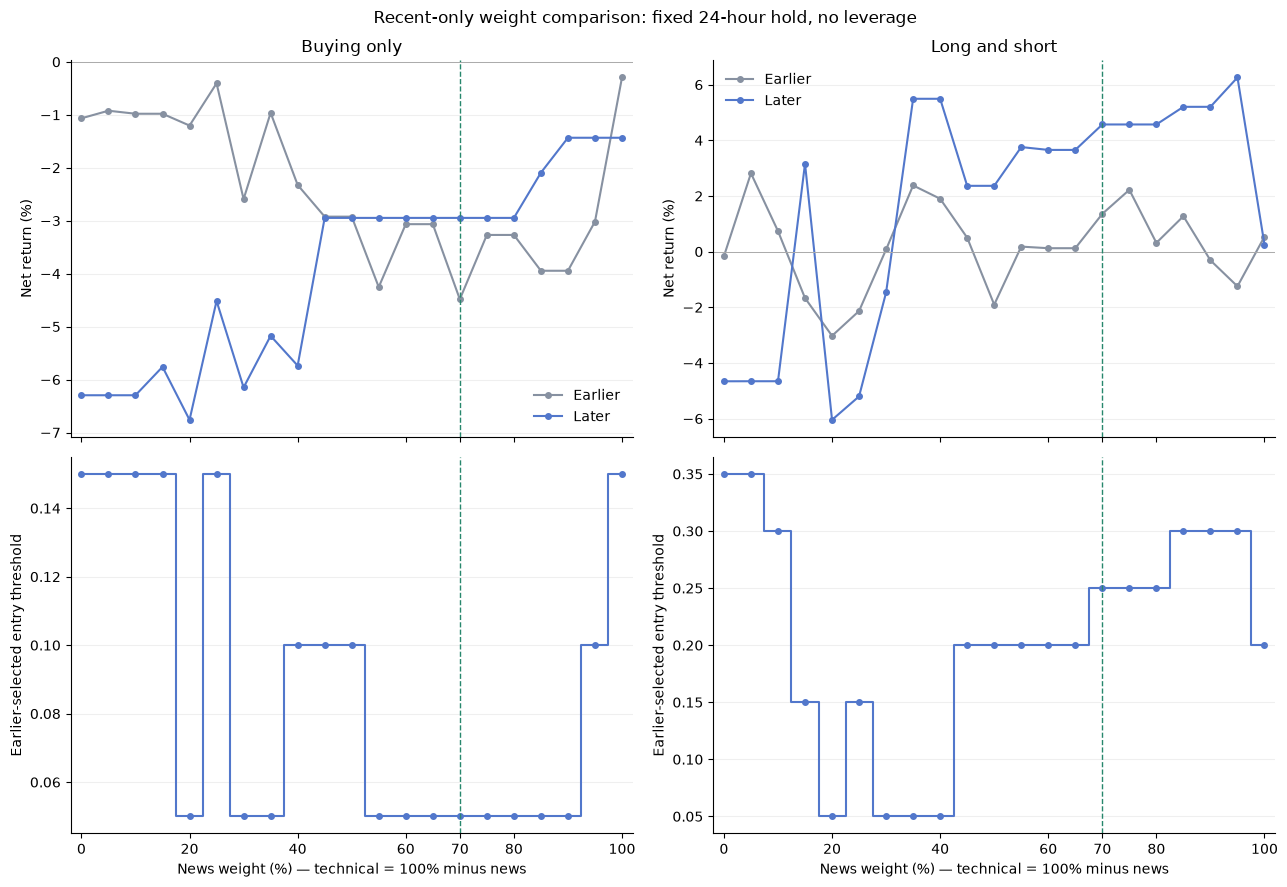

In [25]:
fig,axes=plt.subplots(2,2,figsize=(13,9),sharex=True)
for j,mode in enumerate(MODES):
    part=recent_weight_summary[recent_weight_summary["mode"].eq(mode)].sort_values("news_pct")
    axes[0,j].plot(part.news_pct,part.earlier_return_pct,"o-",ms=4,color="#8791a1",label="Earlier")
    axes[0,j].plot(part.news_pct,part.later_return_pct,"o-",ms=4,color="#5277cb",label="Later")
    axes[0,j].axhline(0,color="#aaaaaa",lw=.7)
    axes[0,j].set_title(mode)
    axes[0,j].set_ylabel("Net return (%)")
    axes[0,j].legend(frameon=False)
    axes[1,j].step(part.news_pct,part.threshold,where="mid",color="#5277cb")
    axes[1,j].scatter(part.news_pct,part.threshold,s=16,color="#5277cb")
    axes[1,j].set_ylabel("Earlier-selected entry threshold")
    axes[1,j].set_xlabel("News weight (%) — technical = 100% minus news")
    for ax in axes[:,j]:
        ax.axvline(70,color="#27876c",ls="--",lw=1)
        ax.set_xticks([0,20,40,60,70,80,100])
        ax.set_xlim(-2,102)
        ax.grid(axis="y",alpha=.2)
fig.suptitle("Recent-only weight comparison: fixed 24-hour hold, no leverage")
fig.tight_layout()
show_chart(fig,"recent_weight_comparison")

### Earlier-period selection landscape: long/short mode

Grey cells have fewer than 10 earlier completed trades and are ineligible for selection. The remaining cells show earlier
net returns. This landscape illustrates both the weighting and threshold choices; it is not a later-period profit forecast.

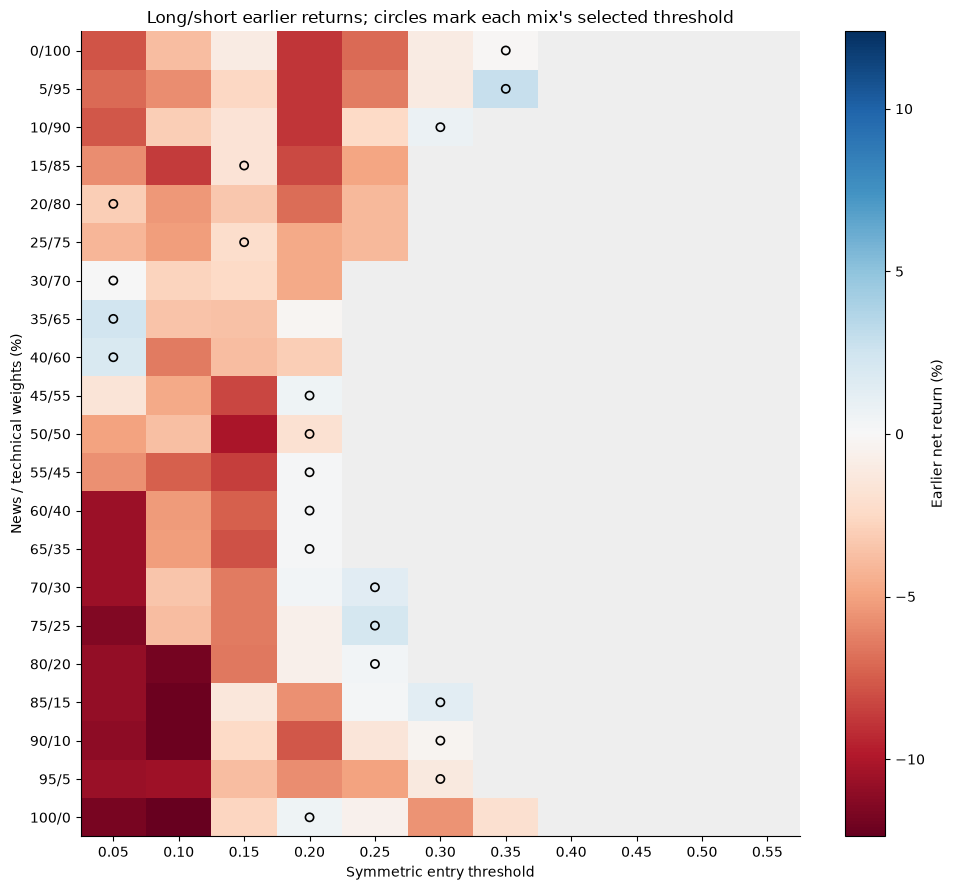

In [26]:
part=recent_weight_grid[recent_weight_grid["mode"].eq("Long and short")&recent_weight_grid.segment.eq("Earlier")]
values=part.pivot(index="news_pct",columns="threshold",values="return_pct").loc[RECENT_NEWS_WEIGHTS,THRESHOLD_GRID]
counts=part.pivot(index="news_pct",columns="threshold",values="trades").loc[RECENT_NEWS_WEIGHTS,THRESHOLD_GRID]
masked=np.ma.masked_where(counts.to_numpy()<MIN_TRAINING_TRADES,values.to_numpy())
cmap=plt.get_cmap("RdBu").copy();cmap.set_bad("#eeeeee")
limit=float(np.abs(masked.compressed()).max())
fig,ax=plt.subplots(figsize=(10,9))
image=ax.imshow(masked,cmap=cmap,vmin=-limit,vmax=limit,aspect="auto")
ax.set_xticks(range(len(THRESHOLD_GRID)),[f"{t:.2f}" for t in THRESHOLD_GRID])
ax.set_yticks(range(len(RECENT_NEWS_WEIGHTS)),[f"{w}/{100-w}" for w in RECENT_NEWS_WEIGHTS])
for i,w in enumerate(RECENT_NEWS_WEIGHTS):
    row=weight_selections[weight_selections["mode"].eq("Long and short")&weight_selections.news_pct.eq(w)].iloc[0]
    ax.scatter(THRESHOLD_GRID.index(float(row.threshold)),i,s=35,facecolors="none",edgecolors="black",linewidths=1.2)
ax.set_xlabel("Symmetric entry threshold")
ax.set_ylabel("News / technical weights (%)")
ax.set_title("Long/short earlier returns; circles mark each mix's selected threshold")
fig.colorbar(image,ax=ax,label="Earlier net return (%)")
fig.tight_layout()
show_chart(fig,"recent_weight_training_landscape")

### Comparison with 70/30 and checks

The table below shows reference mixes plus the pair selected on earlier data. All 21 mixes remain available in the full
tables and CSV exports. Entry-set overlap compares later-period `(entry time, direction)` pairs with 70/30: identical
pairs give an overlap of one. Similar outcomes from the same trades are not independent confirmation.

The three previously approved signal studies must remain unchanged. Additionally, at the same fixed threshold and 24-hour
hold, the 0/100, 70/30 and 100/0 cases must reconcile exactly with the existing TA, P-score and news engines respectively.

In [27]:
selected_weights=set(training_weight_choices.news_pct.astype(int))|{0,30,35,50,60,65,70,75,80,85,100}
display(recent_weight_summary[recent_weight_summary["mode"].eq("Long and short")&recent_weight_summary.news_pct.isin(selected_weights)][[
    "news_pct","technical_pct","threshold","earlier_trades","earlier_return_pct","later_trades",
    "later_return_pct","full_recent_return_pct","later_entry_overlap_with_70_30"]].round(3))

weight_checks=[]
def weight_check(name,condition):
    assert bool(condition),name
    weight_checks.append(dict(check=name,result="PASS"))
weight_check("21 mixes and 11 thresholds in both modes and three segments",len(recent_weight_grid)==1386)
for mode in MODES:
    for news_pct in RECENT_NEWS_WEIGHTS:
        row=weight_selections[weight_selections["mode"].eq(mode)&weight_selections.news_pct.eq(news_pct)].iloc[0]
        eligible=recent_weight_grid[recent_weight_grid["mode"].eq(mode)&recent_weight_grid.news_pct.eq(news_pct)&
            recent_weight_grid.segment.eq("Earlier")&recent_weight_grid.trades.ge(MIN_TRAINING_TRADES)]
        assert row.earlier_trades>=MIN_TRAINING_TRADES
        assert np.isclose(row.earlier_return_pct,eligible.return_pct.max())
        for segment,begin,end in SEGMENTS:
            run=simulate_recent_score(WEIGHT_SCORE_COLUMNS[news_pct],float(row.threshold),WEIGHT_HOLD_HOURS,mode,begin,end)
            t=run["trades"]
            if t.empty:
                continue
            actual=signals[WEIGHT_SCORE_COLUMNS[news_pct]].iloc[t.source_row.astype(int)].to_numpy()
            assert np.allclose(t.signal_score,actual)
            assert (t.signal_score*t.side>=float(row.threshold)-1e-12).all()
            assert t.entry_time.gt(t.signal_time).all()
            assert (t.exit_time-t.entry_time).eq(pd.Timedelta(hours=24)).all()
            assert (t.entry_time.iloc[1:].to_numpy()>=t.exit_time.iloc[:-1].to_numpy()).all()
            assert np.allclose(t.quantity*t.entry_fill*(1+FEE_RATE),t.initial_equity)
            independent=t.initial_equity-t.quantity*t.entry_fill*FEE_RATE+t.side*t.quantity*(t.exit_fill-t.entry_fill)-t.quantity*t.exit_fill*FEE_RATE
            assert np.allclose(independent,t.ending_equity)
            assert abs((np.prod(1+t.net_return)-1)*100-run["metrics"]["return_pct"])<1e-8
            if segment=="Earlier":assert t.exit_time.lt(RECENT_SPLIT).all()
            if segment=="Later":assert t.signal_time.ge(RECENT_SPLIT).all()
for news_pct,original_column in [(0,"ta_score"),(70,"p_score"),(100,"news_score")]:
    for mode in MODES:
        for threshold in THRESHOLD_GRID:
            for segment,begin,end in SEGMENTS:
                blended=simulate_recent_score(WEIGHT_SCORE_COLUMNS[news_pct],threshold,24,mode,begin,end)
                original=simulate_recent_score(original_column,threshold,24,mode,begin,end)
                assert blended["metrics"]["trades"]==original["metrics"]["trades"]
                assert abs(blended["metrics"]["return_pct"]-original["metrics"]["return_pct"])<1e-9
for name in ["Earlier-only threshold selection with 10-trade minimum","Correct weighted score drives each trade",
             "Forward entries, fixed exits, non-overlap and segment boundaries","No leverage and independent fee/P&L accounting",
             "0/100, 70/30 and 100/0 reconcile to the approved source models"]:
    weight_check(name,True)
weight_validation=pd.DataFrame(weight_checks)
display(weight_validation)
weight_validation.to_csv(RESULTS_DIR/"recent_weight_checks.csv",index=False)
weight_summary_output=dict(approved_analysis="Recent-only 21 news/TA mixes, fixed 24-hour hold",
    observations=RECENT_N,earlier_observations=RECENT_CUT,later_observations=RECENT_N-RECENT_CUT,
    split_utc=str(RECENT_SPLIT),news_weights=RECENT_NEWS_WEIGHTS,thresholds=THRESHOLD_GRID,holding_hours=24,
    minimum_earlier_trades=MIN_TRAINING_TRADES,fee_per_side=FEE_RATE,slippage_per_side=SLIPPAGE_RATE,leverage=1,
    training_selected_mixes=json.loads(training_weight_choices.to_json(orient="records")),
    per_mix_results=json.loads(recent_weight_summary.to_json(orient="records")),
    checks_passed=len(weight_validation),
    limitations="Already-inspected data and very few later trades; no untouched holdout. Raw component scales differ. No funding, borrowing, margin or liquidation model. No additional fold or adaptive studies run.")
(RESULTS_DIR/"recent_weight_results.json").write_text(json.dumps(weight_summary_output,indent=2),encoding="utf-8")
print("Approved recent-only weight comparison complete. Further analyses await approval.")

,news_pct,technical_pct,threshold,earlier_trades,earlier_return_pct,later_trades,later_return_pct,full_recent_return_pct,later_entry_overlap_with_70_30
21,0,100,0.35,11,-0.164,5,-4.659,-1.690,0.000
22,5,95,0.35,11,2.815,4,-4.657,1.246,0.000
27,30,70,0.05,22,0.077,9,-1.468,-0.531,0.077
28,35,65,0.05,20,2.378,9,5.492,4.925,0.077
31,50,50,0.20,11,-1.905,5,2.364,4.582,0.429
33,60,40,0.20,11,0.123,6,3.654,7.926,0.571
34,65,35,0.20,11,0.123,6,3.654,3.781,0.571
35,70,30,0.25,10,1.357,5,4.569,5.988,1.000
36,75,25,0.25,11,2.221,5,4.569,6.891,1.000
37,80,20,0.25,14,0.315,5,4.569,4.898,1.000


,check,result
0,21 mixes and 11 thresholds in both modes and t...,PASS
1,Earlier-only threshold selection with 10-trade...,PASS
2,Correct weighted score drives each trade,PASS
3,"Forward entries, fixed exits, non-overlap and ...",PASS
4,No leverage and independent fee/P&L accounting,PASS
5,"0/100, 70/30 and 100/0 reconcile to the approv...",PASS


Approved recent-only weight comparison complete. Further analyses await approval.


### Readout of this frozen recent-data comparison

The earlier-selection winner for long/short trading is **5/95 news/TA**, with threshold **0.35**. It returned **+2.82%** on 11 earlier trades, then **-4.66%** on 4 later trades. The earlier winner did not carry its positive result into the later segment.

The original **70/30** mix selected threshold **0.25** and returned **+4.57%** on 5 later trades. The 70/30, 75/25 and 80/20 mixes produce identical later entry-time/direction sets here, so their matching later returns are not independent confirmation.

The highest later-only return belongs to **95/5**, at **+6.26%** on 6 trades. Its earlier return was **-1.25%**. It was not the earlier-selection winner; choosing it because its later return is highest would be hindsight selection.

All 21 earlier-selected buying-only configurations lost money in the later period. The highest eligible earlier buying-only return was also negative. A weight should not be declared optimal from this small, repeatedly explored sample. No new folds or adaptive-weight tests have been run in this approved step.


## Current interpretation and approval boundary

Completed with approval: recent-only data audit; combined and separate score/correlation views; separate P-score, news-only
and TA-only threshold/holding studies; and **21 news/TA mixes with fixed 24-hour holds and earlier-selected thresholds**.

There is no pristine untouched holdout in this repeatedly explored dataset. Interpret weighting differences alongside trade
counts, costs, drawdowns and entry-set overlap. Do not choose a mix solely because it has the highest later-period return.
Full and segmented replays can differ because boundary-crossing trades are excluded in segmented checks.

**Stop here.** Additional chronological folds, cost/delay stress, new filters, leverage/futures modeling or other analyses
require separate approval. The application and original source data remain unchanged.